# Checks (Alaska): coherence loss / phase closure vs. soil-moisture differences

Same sanity check as [`Checks.ipynb`](Checks.ipynb) (the De Zan model's core
assumption behind `NISAR_SM.ipynb`: coherence loss between two acquisitions
should track the real soil-moisture *difference* between them, and phase closure
magnitude should track the SM *range* across a triplet) -- but for Alaska, and
reading the **already-computed** NISAR coherence/closure-phase CSVs from
`Earsel26_NISAR-main/notebooks/nisar_data/alaska_GSLC_coherence_closure/`
(written by that repo's notebook 04) instead of recomputing coherence from the
raw GSLC stack the way `Checks.ipynb` does for Spain.

Uses each station's own in-situ SNOTEL/USCRN soil-moisture series
(`ismn_data/alaska/station_data/{station}_ts_{depth}.csv`) -- ground truth
independent of `NISAR_SM.ipynb`'s own SAR-derived output, same as the Spain
version. **Both depths are compared** (~5cm main, ~20cm secondary), matching
Spain's convention -- an earlier version of this notebook incorrectly claimed
Alaska's SNOTEL stations only report ~20cm; they report both, confirmed against
the raw ISMN zip (`SNOTEL/.../..._sm_0.050800_0.050800_..._.stm` alongside the
`_0.203200_0.203200_` file), it just wasn't being extracted (see
`01_download_ismn_data.ipynb`'s now-fixed depth query).

**Differences from the Spain `Checks.ipynb`**, driven by real differences in the
Alaska data, not stylistic choices:
- **Multiple tracks per station.** Alaska stations are typically covered by
  several different NISAR relative orbits (unlike Spain's single-track stack),
  already reflected in the precomputed CSVs' `orbit_num` column -- pairs/triplets
  are never formed *across* tracks (the precomputed CSVs already enforce that),
  but a station's scatter plot here pools every track's pairs together, colored
  by `orbit_num` for visibility.
- **In-situ format.** Alaska's SNOTEL/USCRN series (`datetime_UTC,sm_<depth>`)
  has irregular timestamps (readings every 1-2 hours, not the hourly-on-the-hour
  XMS-CAT convention `Checks.ipynb` interpolates against), so the interpolation
  here brackets whatever the two nearest real readings are and caps how far
  apart they're allowed to be, rather than assuming fixed HH:00/(HH+1):00 slots.
- **Same-pass adjacent-frame pairs/triplets are dropped** (`MIN_BASELINE_DAYS`
  in `join_and_compare`, Section 4). `nisar_gslc_windows.py` deliberately saves
  same-overpass adjacent-frame acquisitions as separate files rather than
  merging them (unlike the GCOV pipeline), so a station's sequential-pair/
  triplet logic can end up pairing an acquisition against its own same-pass
  neighbor, seconds (sometimes 0 seconds) apart -- e.g. GraniteCrk tracks 87/92.
  A linear interpolation of the in-situ series necessarily returns ~identical SM
  values for two timestamps that close together, so left in, these rows would
  be structurally guaranteed `dsm~=0` regardless of the true soil moisture --
  not a real test of the De Zan hypothesis, just noise with a misleading shape.
- **No backscatter/time-series sections.** Those need the raw GSLC pixel stack,
  which this notebook deliberately never touches -- the whole point here is to
  reuse the coherence/closure-phase numbers already computed, not recompute them.

In [1]:
import sys
import os
from pathlib import Path

import pyproj
pyproj.datadir.set_data_dir(os.path.join(sys.prefix, "Library", "share", "proj"))


def require_globals(*names):
    missing = [n for n in names if n not in globals()]
    if missing:
        raise RuntimeError(
            f"Missing {missing} -- run the earlier setup cells first "
            "(the kernel may have been restarted)."
        )


BASE = Path.cwd()
EARSEL_NOTEBOOKS = BASE / "Earsel26_NISAR-main" / "notebooks"
COH_CLOSURE_DIR = EARSEL_NOTEBOOKS / "nisar_data" / "alaska_GSLC_coherence_closure"
INSITU_DIR = EARSEL_NOTEBOOKS / "ismn_data" / "alaska" / "station_data"


C:\Users\geoka\miniconda3\envs\nisar-era5\Lib\site-packages\pyproj\network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


## 1. Station list

In [2]:
require_globals("EARSEL_NOTEBOOKS")

import json

stations_path = EARSEL_NOTEBOOKS / "ismn_data" / "alaska" / "stations.geojson"
with open(stations_path) as f:
    stations_geojson = json.load(f)

station_names = [feat["properties"]["station_val"] for feat in stations_geojson["features"]]
print(f"Loaded {len(station_names)} station names")
station_names

Loaded 20 station names


['MooseInc',
 'Aniak',
 'AtigunPass',
 'Coldfoot',
 'EagleSummit',
 'GobblersKnob',
 'GraniteCrk',
 'ImnaviatCreek',
 'LittleChenaRidge',
 'McGrath',
 'Nenana',
 'NukaGlacier',
 'PilgrimHotSprings',
 'PrudhoeBay',
 'RockyPoint',
 'SpringCreek',
 'SusitnaValleyHigh',
 'TurnagainPass',
 'UpperNomeCreek',
 'Kenai-29-ENE']

## 2. In-situ SM reader and a generic bracket-interpolator

`{station}_ts_{depth}.csv` (written per station *and per depth* by the fixed
`01_prepare_ismn_data.ipynb`) has irregular timestamps (real sensor reporting
times, not a fixed hourly grid) -- `interp_insitu_at` finds the nearest real
reading before and after the target time and linearly interpolates between them,
returning NaN if there's no reading on one side or the bracketing gap exceeds
`MAX_GAP_HOURS` (avoids quietly interpolating across a real data outage and
calling it a measurement).

In [3]:
require_globals("INSITU_DIR", "station_names")

import numpy as np
import pandas as pd

MAX_GAP_HOURS = 6
DEPTH_MAIN = 0.05   # matches the 5cm "main" comparison depth used for Spain
DEPTH_SECONDARY = 0.20

JUMP_THRESHOLD = 0.08  # 8 percentage points/hour -- real volumetric SM can't move this fast
FAULT_CEILING = 0.08   # a bracketed low plateau only counts as a fault if it stays this implausibly low throughout
MAX_BRIDGE_DAYS = 30
MIN_READINGS = 200     # RockyPoint's 20cm file has only 53 valid readings (every other station/depth has 1200-2255) -- too sparse to be a meaningful comparison

def read_insitu(station, depth):
    path = INSITU_DIR / f"{station}_ts_{depth:.2f}.csv"
    if not path.exists():
        return None
    df = pd.read_csv(path, index_col=0, parse_dates=True)
    series = df.iloc[:, 0].sort_index()  # single sm_<depth> column, whatever it's named

    # Sensor-fault plateaus (e.g. ImnaviatCreek 5cm 2026-07-23->08-03, stuck
    # near 0.1-0.2%; RockyPoint 5cm 2026-07-18->07-20, stuck near 1-5%) are
    # bracketed by physically impossible single-step jumps on both sides (real
    # volumetric SM can't move this fast) with an implausibly low interior
    # throughout -- mask everything between a big drop and the next big rise
    # that follows it, but only when that whole interior stays below
    # FAULT_CEILING. A fast-but-real wet-up/dry-down (e.g. EagleSummit's 20cm
    # 6-day dip to 14-19%) has the same jump signature but a physically
    # plausible interior, so it's left alone -- a plain magnitude threshold on
    # its own can't tell these apart (checked against every station/depth
    # here before picking these constants).
    diffs = series.diff()
    drops = series.index[diffs < -JUMP_THRESHOLD]
    rises = series.index[diffs > JUMP_THRESHOLD]
    for drop_ts in drops:
        later_rises = rises[rises > drop_ts]
        if len(later_rises) == 0:
            continue
        rise_ts = later_rises[0]
        if (rise_ts - drop_ts) > pd.Timedelta(days=MAX_BRIDGE_DAYS):
            continue
        span = series.loc[drop_ts:rise_ts].iloc[:-1]  # exclude the recovery reading itself
        if span.max() < FAULT_CEILING:
            series.loc[span.index] = np.nan

    # Exact 0.0 (or negative) is never a plausible reading on its own either,
    # even outside a bracketed fault window.
    series = series.mask(series <= 0)

    # Too few real readings to interpolate a meaningful comparison from (e.g.
    # RockyPoint's 20cm sensor) -- treat the same as "no data" rather than
    # feeding a handful of points into the comparison.
    if series.notna().sum() < MIN_READINGS:
        return None

    return series


def interp_insitu_at(series, ts):
    before = series.loc[:ts]
    after = series.loc[ts:]
    if before.empty or after.empty:
        return np.nan
    t0, v0 = before.index[-1], before.iloc[-1]
    t1, v1 = after.index[0], after.iloc[0]
    if t0 == t1:
        return float(v0)
    gap_hours = (t1 - t0).total_seconds() / 3600.0
    if gap_hours > MAX_GAP_HOURS:
        return np.nan
    frac = (ts - t0).total_seconds() / (t1 - t0).total_seconds()
    return float(v0 + frac * (v1 - v0))


for depth in (DEPTH_MAIN, DEPTH_SECONDARY):
    n_found = sum(1 for s in station_names if read_insitu(s, depth) is not None)
    print(f"depth {depth:.2f}m: {n_found}/{len(station_names)} station(s) have a series")


depth 0.05m: 18/20 station(s) have a series
depth 0.20m: 16/20 station(s) have a series


## 3. Load the precomputed coherence and closure-phase CSVs

Reads `{station}_NISAR_GSLC_coherence.csv`/`_closure_phase.csv` directly --
these already exist from
[`Earsel26_NISAR-main/notebooks/04_calc_coh_phase_closure_NISAR.ipynb`](Earsel26_NISAR-main/notebooks/04_calc_coh_phase_closure_NISAR.ipynb)
(despite the filename, pointed at Alaska), so this is purely local, no
recomputation, and independent of in-situ depth (the same two CSVs feed both the
5cm and 20cm comparisons below).

In [4]:
require_globals("COH_CLOSURE_DIR", "station_names")

DATE_COLS_PAIRS = ["date_1", "date_2"]
DATE_COLS_TRIPLETS = ["date_1", "date_2", "date_3"]

coherence_by_station = {}
closure_by_station = {}
for station in station_names:
    coh_path = COH_CLOSURE_DIR / f"{station}_NISAR_GSLC_coherence.csv"
    clo_path = COH_CLOSURE_DIR / f"{station}_NISAR_GSLC_closure_phase.csv"
    if not coh_path.exists() or not clo_path.exists():
        print(f"{station}: missing coherence/closure CSV, skipping")
        continue
    df_coh = pd.read_csv(coh_path)
    df_clo = pd.read_csv(clo_path)
    for col in DATE_COLS_PAIRS:
        df_coh[col] = pd.to_datetime(df_coh[col])
    for col in DATE_COLS_TRIPLETS:
        df_clo[col] = pd.to_datetime(df_clo[col])
    coherence_by_station[station] = df_coh
    closure_by_station[station] = df_clo
    print(f"{station}: {len(df_coh)} pair(s), {len(df_clo)} triplet(s)")


MooseInc: 36 pair(s), 34 triplet(s)
Aniak: missing coherence/closure CSV, skipping
AtigunPass: 32 pair(s), 28 triplet(s)
Coldfoot: 36 pair(s), 34 triplet(s)
EagleSummit: 52 pair(s), 48 triplet(s)
GobblersKnob: 36 pair(s), 34 triplet(s)
GraniteCrk: 49 pair(s), 45 triplet(s)
ImnaviatCreek: 28 pair(s), 22 triplet(s)
LittleChenaRidge: 57 pair(s), 58 triplet(s)
McGrath: 31 pair(s), 34 triplet(s)
Nenana: missing coherence/closure CSV, skipping
NukaGlacier: 52 pair(s), 48 triplet(s)


PilgrimHotSprings: 65 pair(s), 70 triplet(s)
PrudhoeBay: missing coherence/closure CSV, skipping
RockyPoint: 41 pair(s), 44 triplet(s)
SpringCreek: 34 pair(s), 26 triplet(s)
SusitnaValleyHigh: 40 pair(s), 30 triplet(s)
TurnagainPass: 38 pair(s), 32 triplet(s)
UpperNomeCreek: 57 pair(s), 58 triplet(s)
Kenai-29-ENE: 32 pair(s), 28 triplet(s)


## 4. Join against in-situ SM at a given depth

`join_and_compare(depth)` returns fresh copies of the coherence/closure tables
enriched with `|SM difference|` (pairs) and SM range = `max - min` across the
triplet's three readings (triplets), for that depth -- called once per depth
below, each returning its own independent copy so a 20cm run never overwrites a
5cm run's columns.

In [5]:
require_globals("coherence_by_station", "closure_by_station")

# Backup guard, not the primary fix: nisar_coherence_closure.py's
# load_station_acquisitions now drops same-pass adjacent-frame acquisitions
# (ADJACENT_PASS_GAP_SECONDS apart) *before* forming pairs/triplets, so
# freshly-regenerated alaska_GSLC_coherence_closure/ CSVs (re-run notebook 04)
# shouldn't contain these rows at all anymore. This filter stays as a cheap
# safety net against stale CSVs from before that fix, or a future regression --
# harmless no-op once the upstream data is clean. Originally found via
# GraniteCrk tracks 87/92, where consecutive same-pass acquisitions were 0-8
# seconds apart, giving several pairs a temporal_baseline_days of ~1e-4 or 0 --
# a linear interpolation of a smooth in-situ series necessarily returns
# ~identical SM values for two timestamps that close together, so those rows
# were structurally guaranteed dsm~=0 regardless of the true soil moisture.
MIN_BASELINE_DAYS = 0.01  # ~14 minutes -- comfortably above "seconds apart", well below the ~12-day repeat cycle


def join_and_compare(depth):
    coherence_dfs = {}
    closure_dfs = {}
    for station in coherence_by_station:
        series = read_insitu(station, depth)
        if series is None:
            continue

        df_coh = coherence_by_station[station].copy()
        n_before = len(df_coh)
        df_coh = df_coh[df_coh["temporal_baseline_days"] >= MIN_BASELINE_DAYS].copy()
        if len(df_coh) < n_before:
            print(f"  {station}: dropped {n_before - len(df_coh)} same-pass pair(s) "
                  f"(baseline < {MIN_BASELINE_DAYS} days)")
        df_coh["sm_1"] = df_coh["date_1"].apply(lambda ts: interp_insitu_at(series, ts)) * 100
        df_coh["sm_2"] = df_coh["date_2"].apply(lambda ts: interp_insitu_at(series, ts)) * 100
        df_coh["dsm"] = (df_coh["sm_1"] - df_coh["sm_2"]).abs()
        coherence_dfs[station] = df_coh

        df_clo = closure_by_station[station].copy()
        n_before = len(df_clo)
        df_clo = df_clo[
            (df_clo["temporal_baseline_12_days"] >= MIN_BASELINE_DAYS)
            & (df_clo["temporal_baseline_23_days"] >= MIN_BASELINE_DAYS)
            & (df_clo["temporal_baseline_13_days"] >= MIN_BASELINE_DAYS)
        ].copy()
        if len(df_clo) < n_before:
            print(f"  {station}: dropped {n_before - len(df_clo)} triplet(s) with a same-pass leg "
                  f"(baseline < {MIN_BASELINE_DAYS} days)")
        for col in DATE_COLS_TRIPLETS:
            df_clo[f"sm_{col[-1]}"] = df_clo[col].apply(lambda ts: interp_insitu_at(series, ts)) * 100
        sm_cols = [f"sm_{col[-1]}" for col in DATE_COLS_TRIPLETS]
        # skipna=False: a triplet with only 2 of 3 in-situ readings shouldn't get
        # a "valid-looking" range computed from just those 2 -- the missing date
        # could be more extreme than either, so the true range is unknown, not
        # just narrower.
        df_clo["dsm_range"] = (
            df_clo[sm_cols].max(axis=1, skipna=False) - df_clo[sm_cols].min(axis=1, skipna=False)
        )
        df_clo["abs_closure_phase_HH"] = df_clo["closure_phase_HH"].abs()
        df_clo["abs_closure_phase_HV"] = df_clo["closure_phase_HV"].abs()
        closure_dfs[station] = df_clo

    return coherence_dfs, closure_dfs


## 5. Plot helpers

Pooled across every track for a station (colored by `orbit_num`) -- pairs are
never formed across tracks in the precomputed CSVs, so pooling here only mixes
independent same-track comparisons, not cross-geometry ones.

In [6]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm


def plot_coherence_vs_dsm(coherence_dfs, depth_label, pol):
    coh_col = f"coherence_{pol}"
    station_list = list(coherence_dfs.keys())
    n_stations = len(station_list)
    ncols = 3
    nrows = int((n_stations + ncols - 1) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 5, nrows * 4))
    axes = axes.flatten()

    r_by_station = {}
    for idx, station in enumerate(station_list):
        ax = axes[idx]
        df_v = coherence_dfs[station]
        valid = df_v[coh_col].notna() & df_v["dsm"].notna()
        df_v = df_v.loc[valid]
        x = df_v["dsm"].values
        y = df_v[coh_col].values
        r = np.corrcoef(x, y)[0, 1] if len(x) > 1 else np.nan
        r_by_station[station] = r

        orbits = sorted(df_v["orbit_num"].unique())
        colors = cm.tab10(np.linspace(0, 1, max(len(orbits), 1)))
        for orbit, color in zip(orbits, colors):
            m = df_v["orbit_num"] == orbit
            ax.scatter(df_v.loc[m, "dsm"], df_v.loc[m, coh_col], color=color, s=40,
                       label=f"track {orbit}", zorder=3)
        if len(x) > 1:
            fit = np.polyfit(x, y, 1)
            xs = np.linspace(x.min(), x.max(), 10)
            ax.plot(xs, np.polyval(fit, xs), "--", color="firebrick", linewidth=1.5)
        ax.set_title(f"{station}\nR={r:.2f}")
        ax.set_xlabel("|SM difference| (%)")
        ax.set_ylabel(f"Coherence {pol}")
        ax.legend(fontsize=6, loc="best")
        ax.grid(True, alpha=0.3)

    for idx in range(n_stations, len(axes)):
        axes[idx].axis("off")

    plt.suptitle(f"Coherence ({pol}) vs. in-situ SM difference, Alaska ({depth_label})", fontsize=14)
    plt.tight_layout()
    plt.show()

    print(f"Pearson R (|SM diff| vs coherence_{pol}) per station, {depth_label} -- De Zan predicts negative:")
    for station, r in r_by_station.items():
        print(f"  {station}: R={r:.3f}")
    return r_by_station


def plot_closure_vs_range(closure_dfs, depth_label, pol):
    closure_col = f"abs_closure_phase_{pol}"
    station_list = list(closure_dfs.keys())
    n_stations = len(station_list)
    ncols = 3
    nrows = int((n_stations + ncols - 1) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 5, nrows * 4))
    axes = axes.flatten()

    r_by_station = {}
    for idx, station in enumerate(station_list):
        ax = axes[idx]
        df_v = closure_dfs[station]
        valid = df_v[closure_col].notna() & df_v["dsm_range"].notna()
        df_v = df_v.loc[valid]
        x = df_v["dsm_range"].values
        y = df_v[closure_col].values
        r = np.corrcoef(x, y)[0, 1] if len(x) > 1 else np.nan
        r_by_station[station] = r

        orbits = sorted(df_v["orbit_num"].unique())
        colors = cm.tab10(np.linspace(0, 1, max(len(orbits), 1)))
        for orbit, color in zip(orbits, colors):
            m = df_v["orbit_num"] == orbit
            ax.scatter(df_v.loc[m, "dsm_range"], df_v.loc[m, closure_col], color=color, s=40,
                       label=f"track {orbit}", zorder=3)
        if len(x) > 1:
            fit = np.polyfit(x, y, 1)
            xs = np.linspace(x.min(), x.max(), 10)
            ax.plot(xs, np.polyval(fit, xs), "--", color="firebrick", linewidth=1.5)
        ax.set_title(f"{station}\nR={r:.2f}")
        ax.set_xlabel("SM range across triplet (%)")
        ax.set_ylabel(f"|Phase closure| {pol} (rad)")
        ax.legend(fontsize=6, loc="best")
        ax.grid(True, alpha=0.3)

    for idx in range(n_stations, len(axes)):
        axes[idx].axis("off")

    plt.suptitle(f"Triplet phase closure ({pol}) vs. in-situ SM range, Alaska ({depth_label})", fontsize=14)
    plt.tight_layout()
    plt.show()

    print(f"Pearson R (SM range vs |phase closure_{pol}|) per station, {depth_label} -- De Zan predicts positive:")
    for station, r in r_by_station.items():
        print(f"  {station}: R={r:.3f}")
    return r_by_station


## 6. 5cm depth (main comparison)

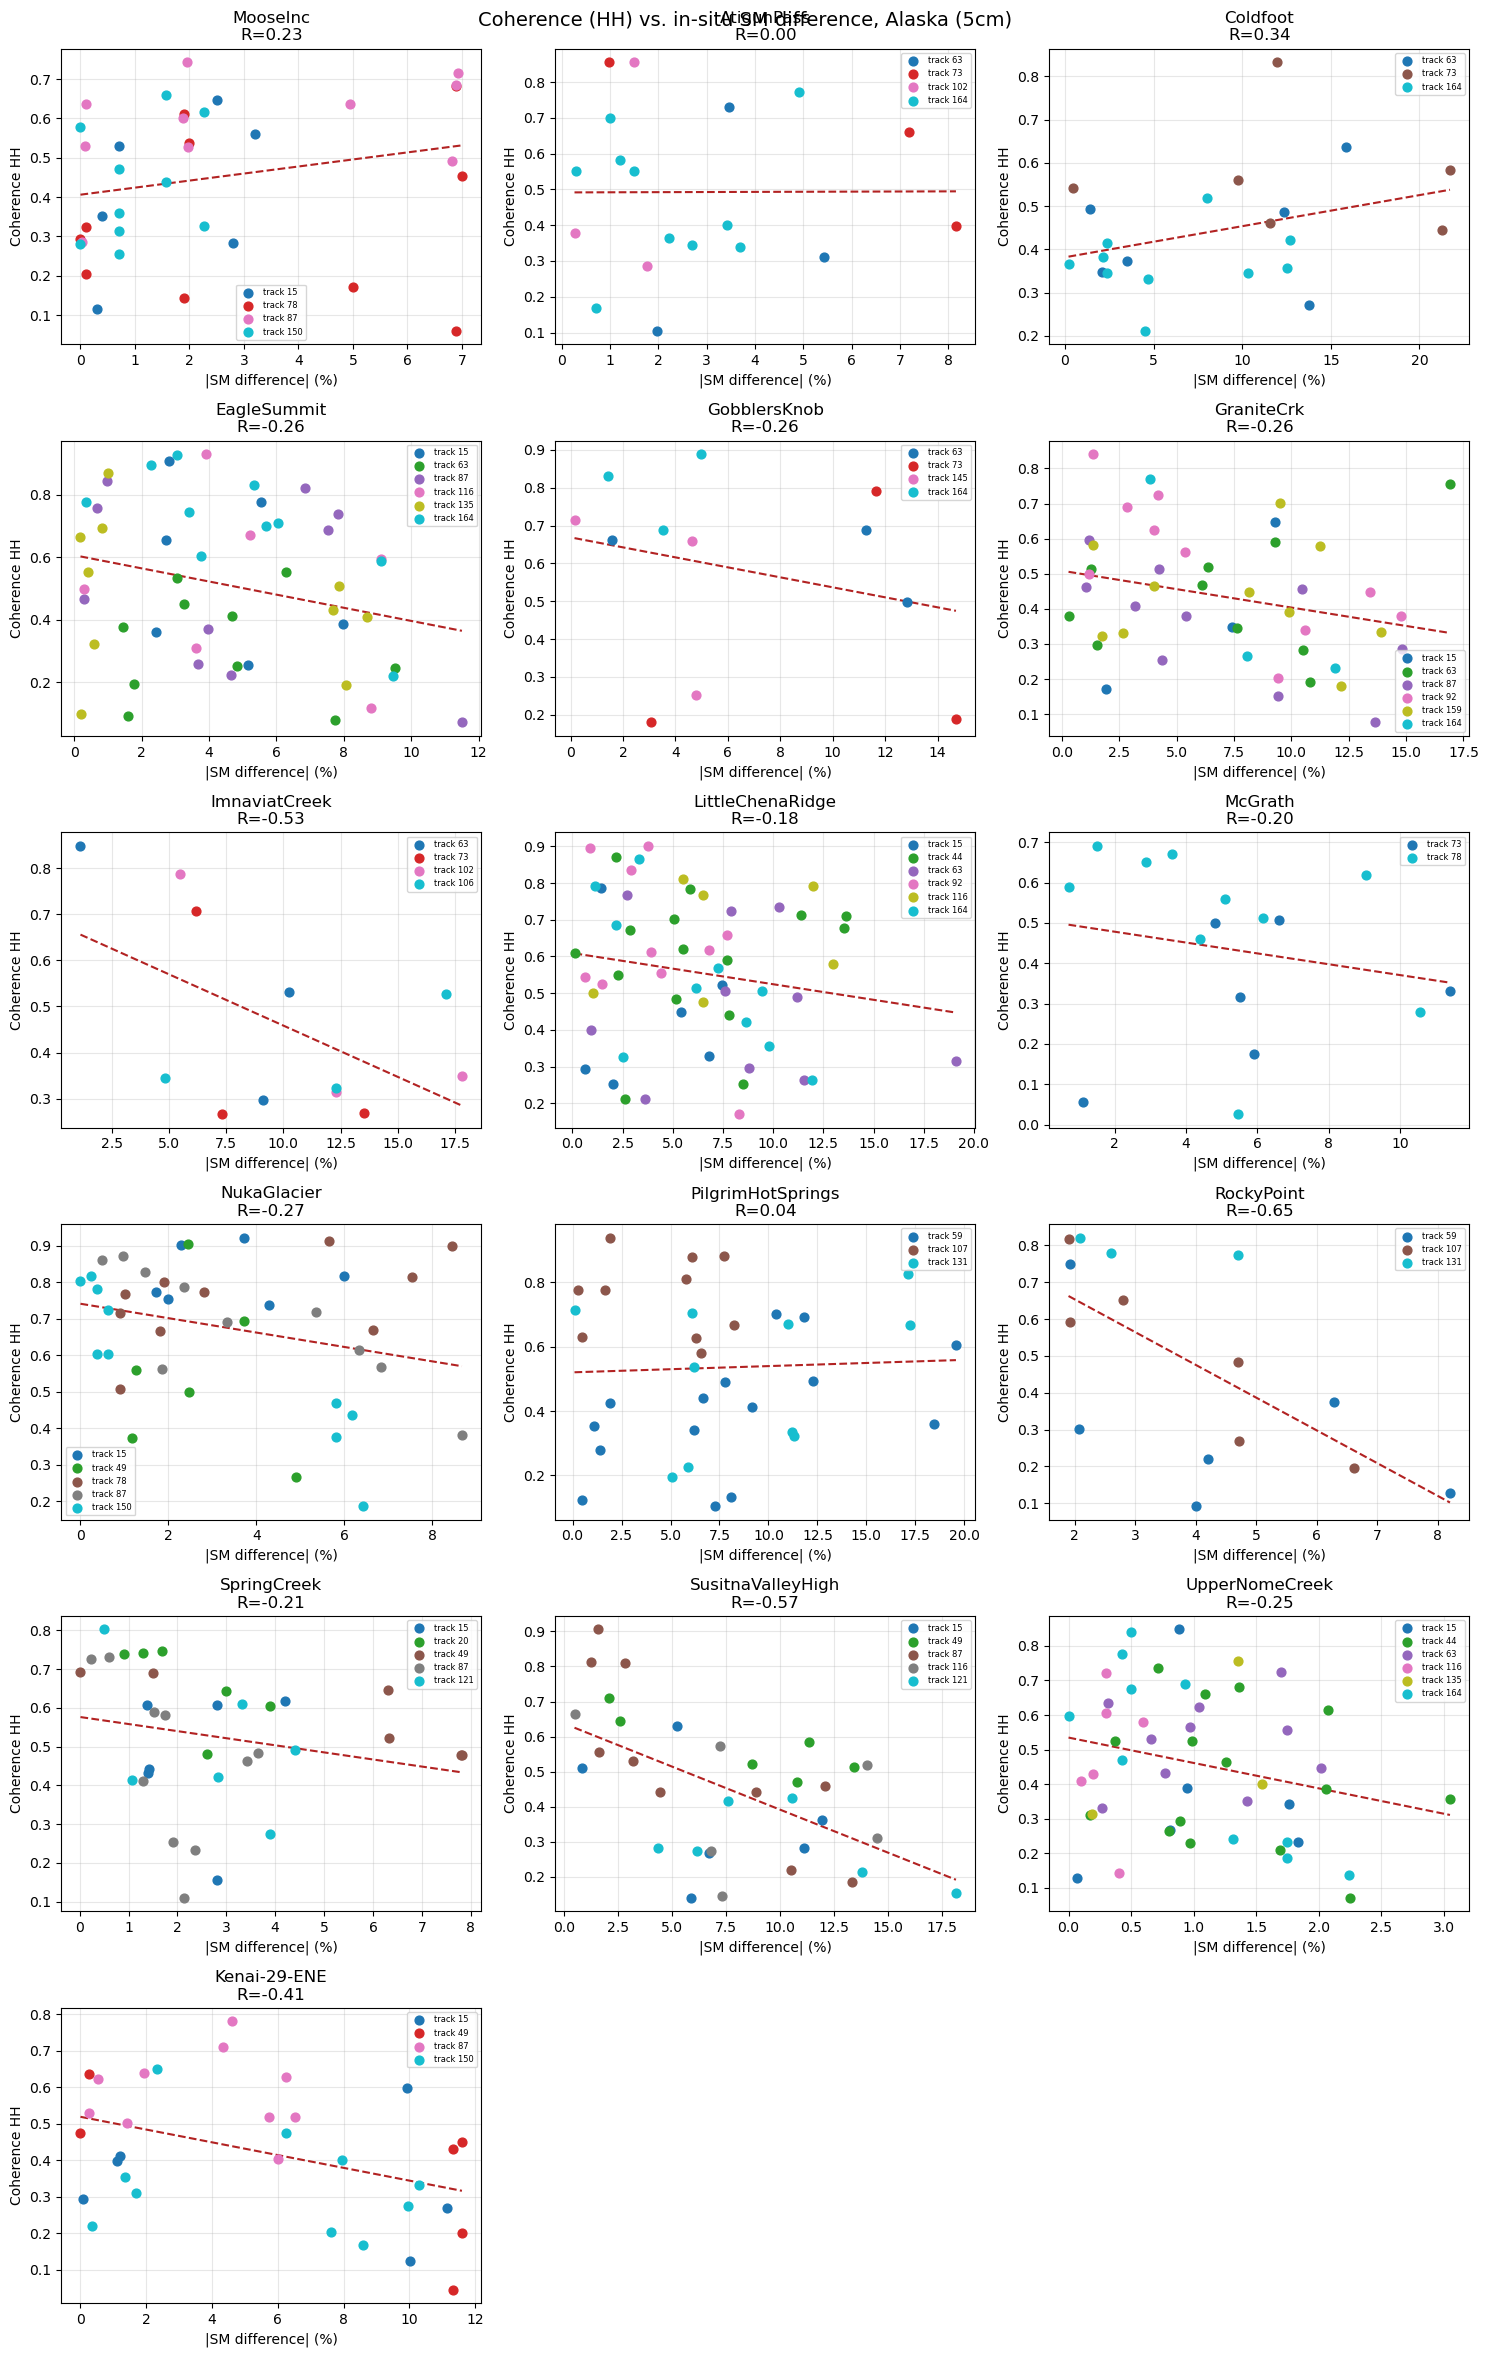

Pearson R (|SM diff| vs coherence_HH) per station, 5cm -- De Zan predicts negative:
  MooseInc: R=0.229
  AtigunPass: R=0.004
  Coldfoot: R=0.344
  EagleSummit: R=-0.256
  GobblersKnob: R=-0.265
  GraniteCrk: R=-0.262
  ImnaviatCreek: R=-0.531
  LittleChenaRidge: R=-0.175
  McGrath: R=-0.196
  NukaGlacier: R=-0.271
  PilgrimHotSprings: R=0.043
  RockyPoint: R=-0.650
  SpringCreek: R=-0.207
  SusitnaValleyHigh: R=-0.573
  UpperNomeCreek: R=-0.251
  Kenai-29-ENE: R=-0.405


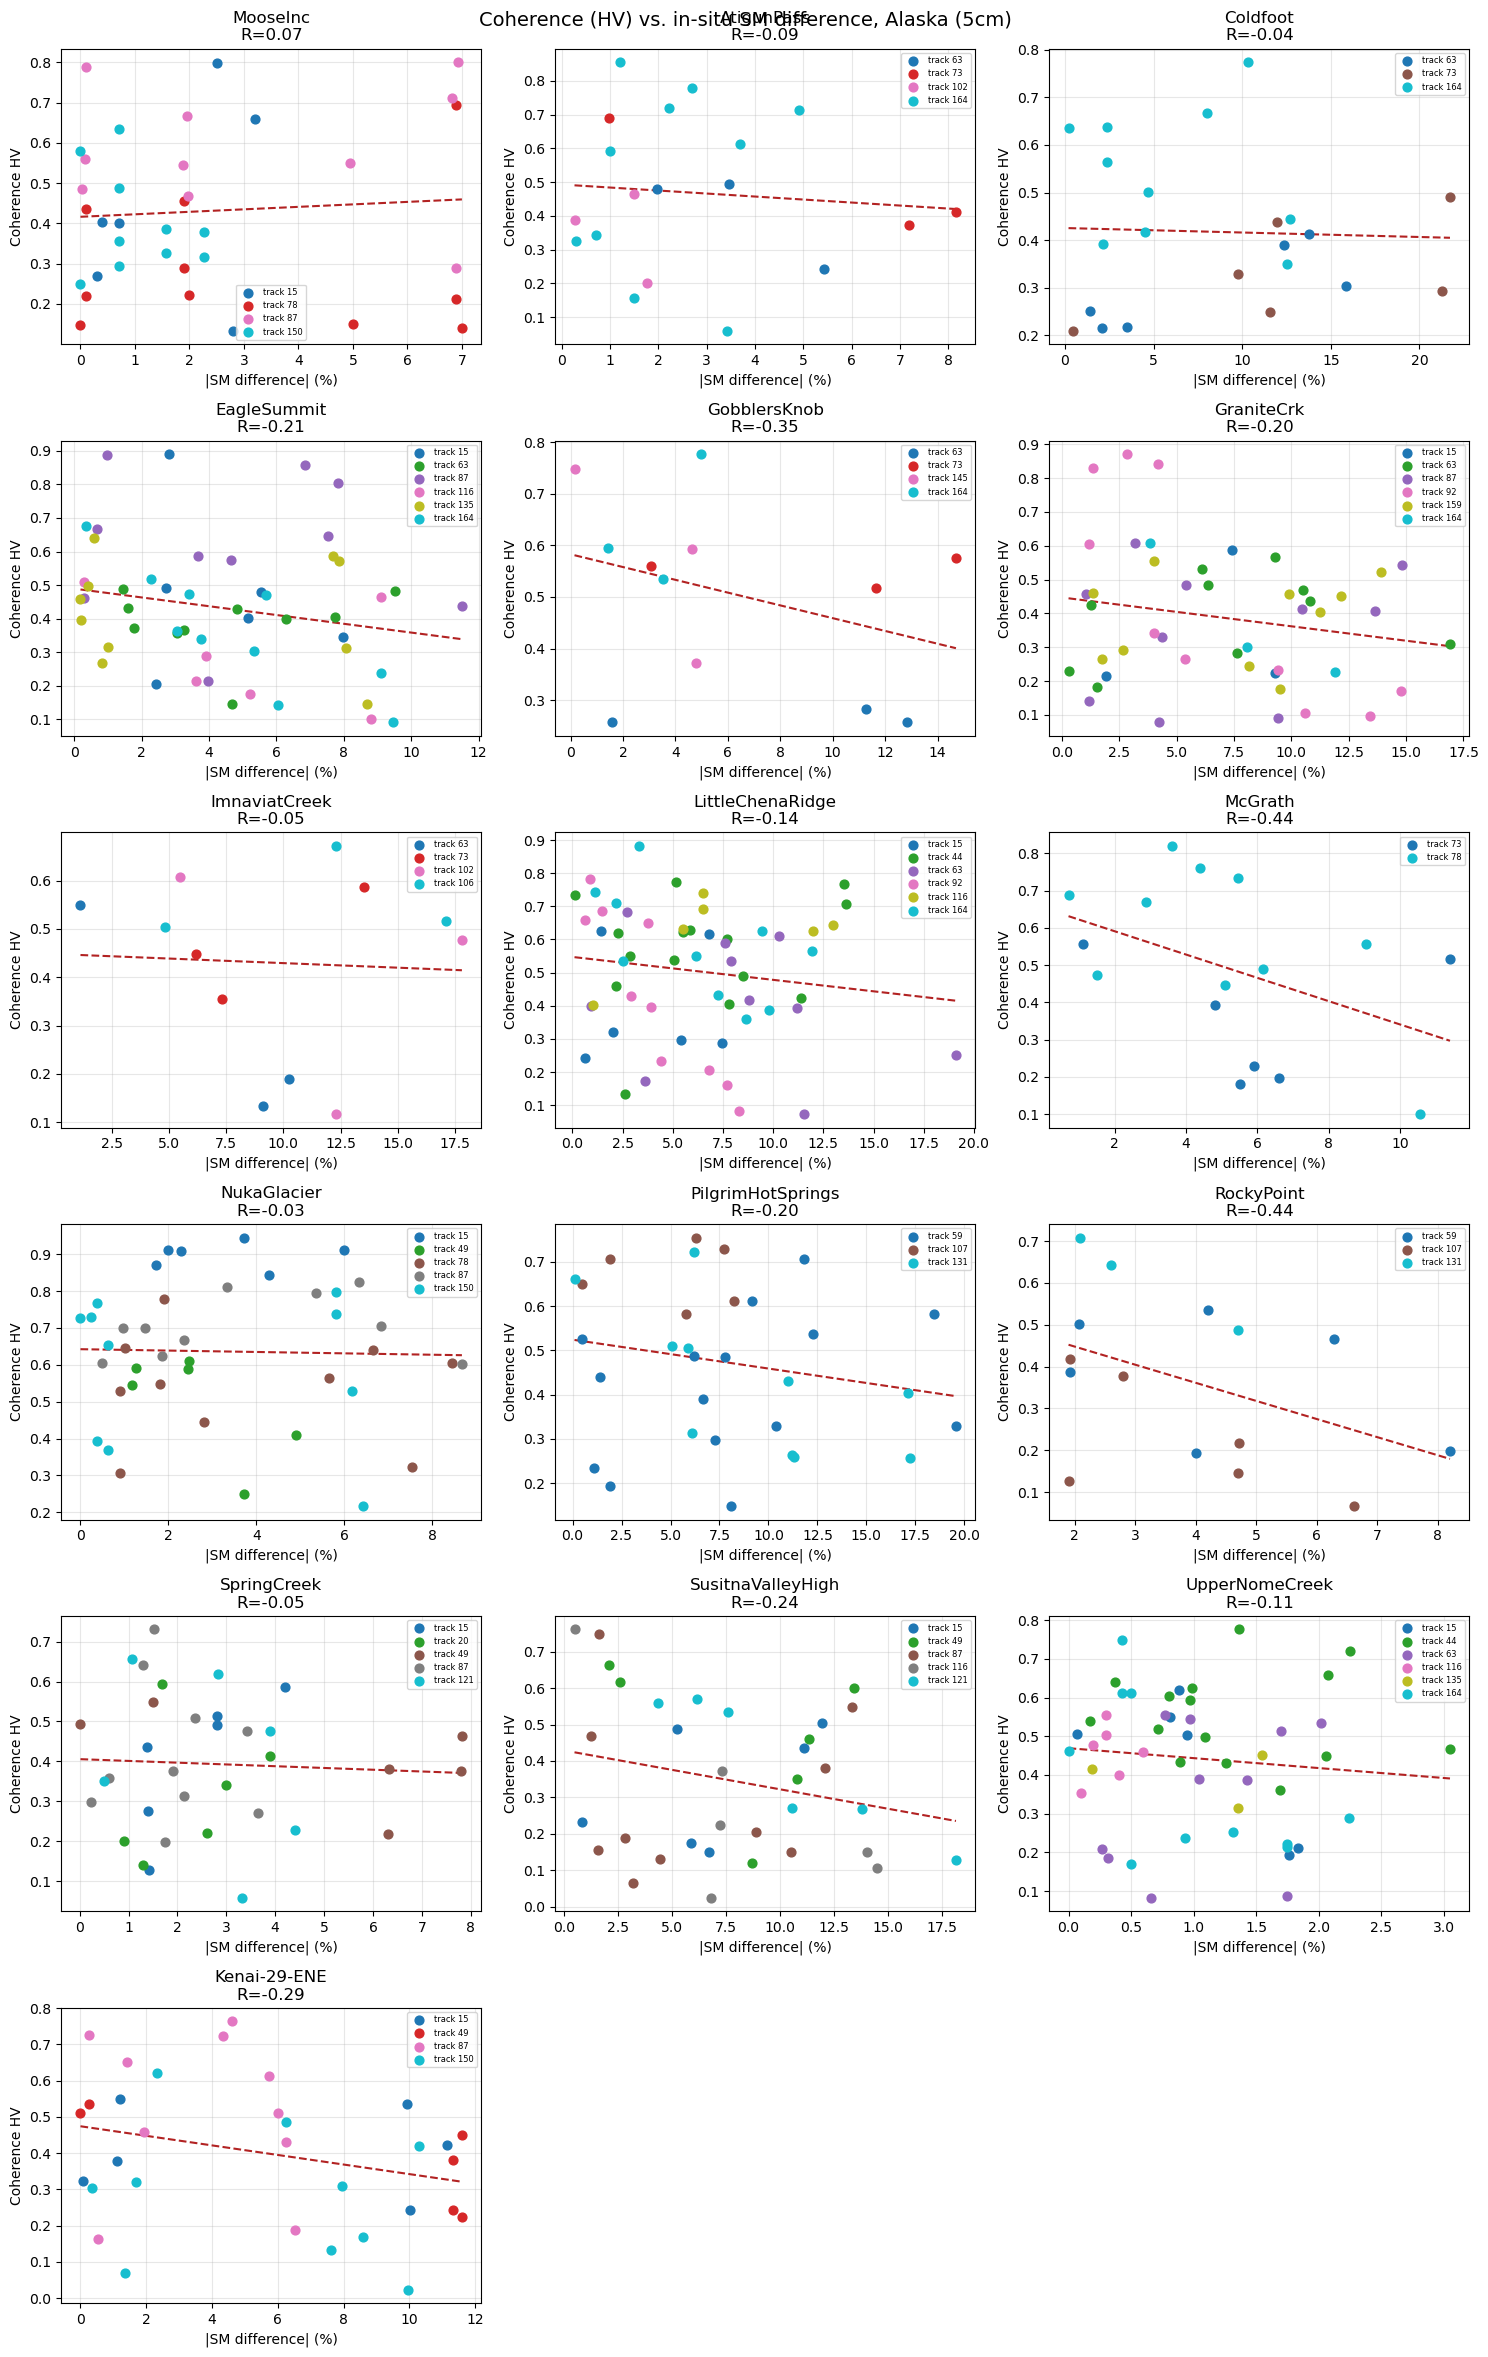

Pearson R (|SM diff| vs coherence_HV) per station, 5cm -- De Zan predicts negative:
  MooseInc: R=0.075
  AtigunPass: R=-0.090
  Coldfoot: R=-0.038
  EagleSummit: R=-0.210
  GobblersKnob: R=-0.348
  GraniteCrk: R=-0.198
  ImnaviatCreek: R=-0.051
  LittleChenaRidge: R=-0.144
  McGrath: R=-0.439
  NukaGlacier: R=-0.026
  PilgrimHotSprings: R=-0.196
  RockyPoint: R=-0.435
  SpringCreek: R=-0.053
  SusitnaValleyHigh: R=-0.239
  UpperNomeCreek: R=-0.106
  Kenai-29-ENE: R=-0.286


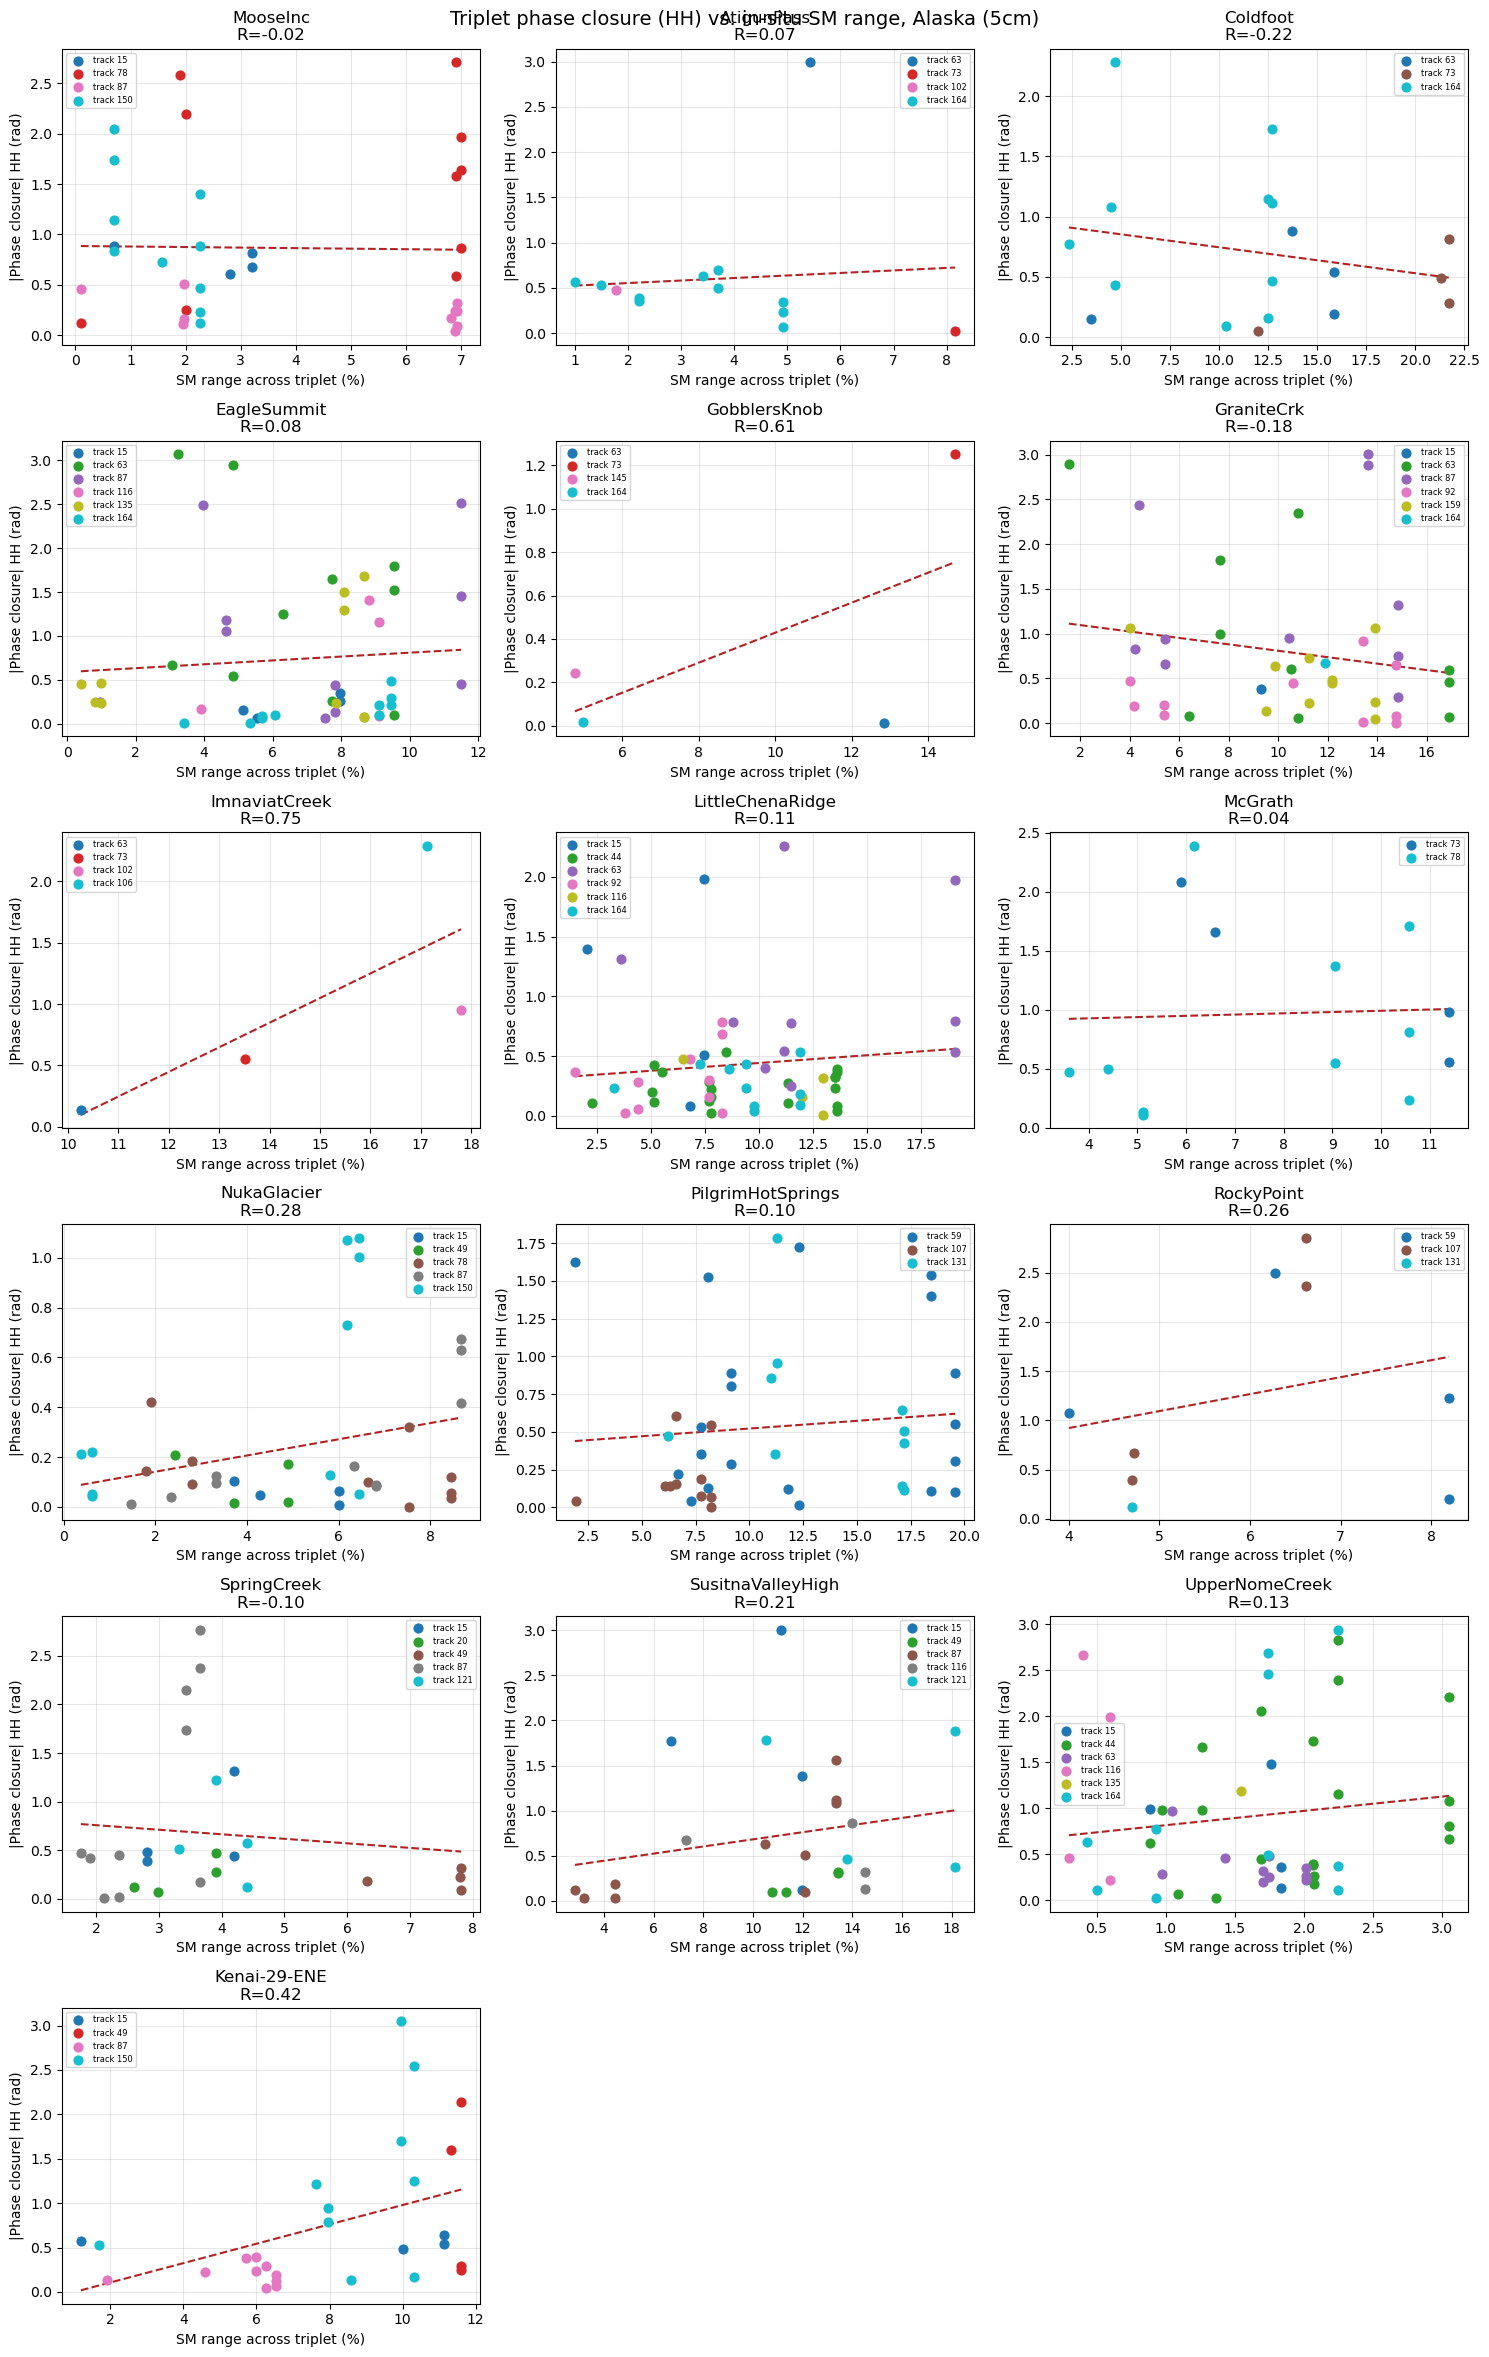

Pearson R (SM range vs |phase closure_HH|) per station, 5cm -- De Zan predicts positive:
  MooseInc: R=-0.018
  AtigunPass: R=0.074
  Coldfoot: R=-0.220
  EagleSummit: R=0.080
  GobblersKnob: R=0.609
  GraniteCrk: R=-0.185
  ImnaviatCreek: R=0.751
  LittleChenaRidge: R=0.109
  McGrath: R=0.040
  NukaGlacier: R=0.283
  PilgrimHotSprings: R=0.100
  RockyPoint: R=0.256
  SpringCreek: R=-0.104
  SusitnaValleyHigh: R=0.213
  UpperNomeCreek: R=0.128
  Kenai-29-ENE: R=0.425


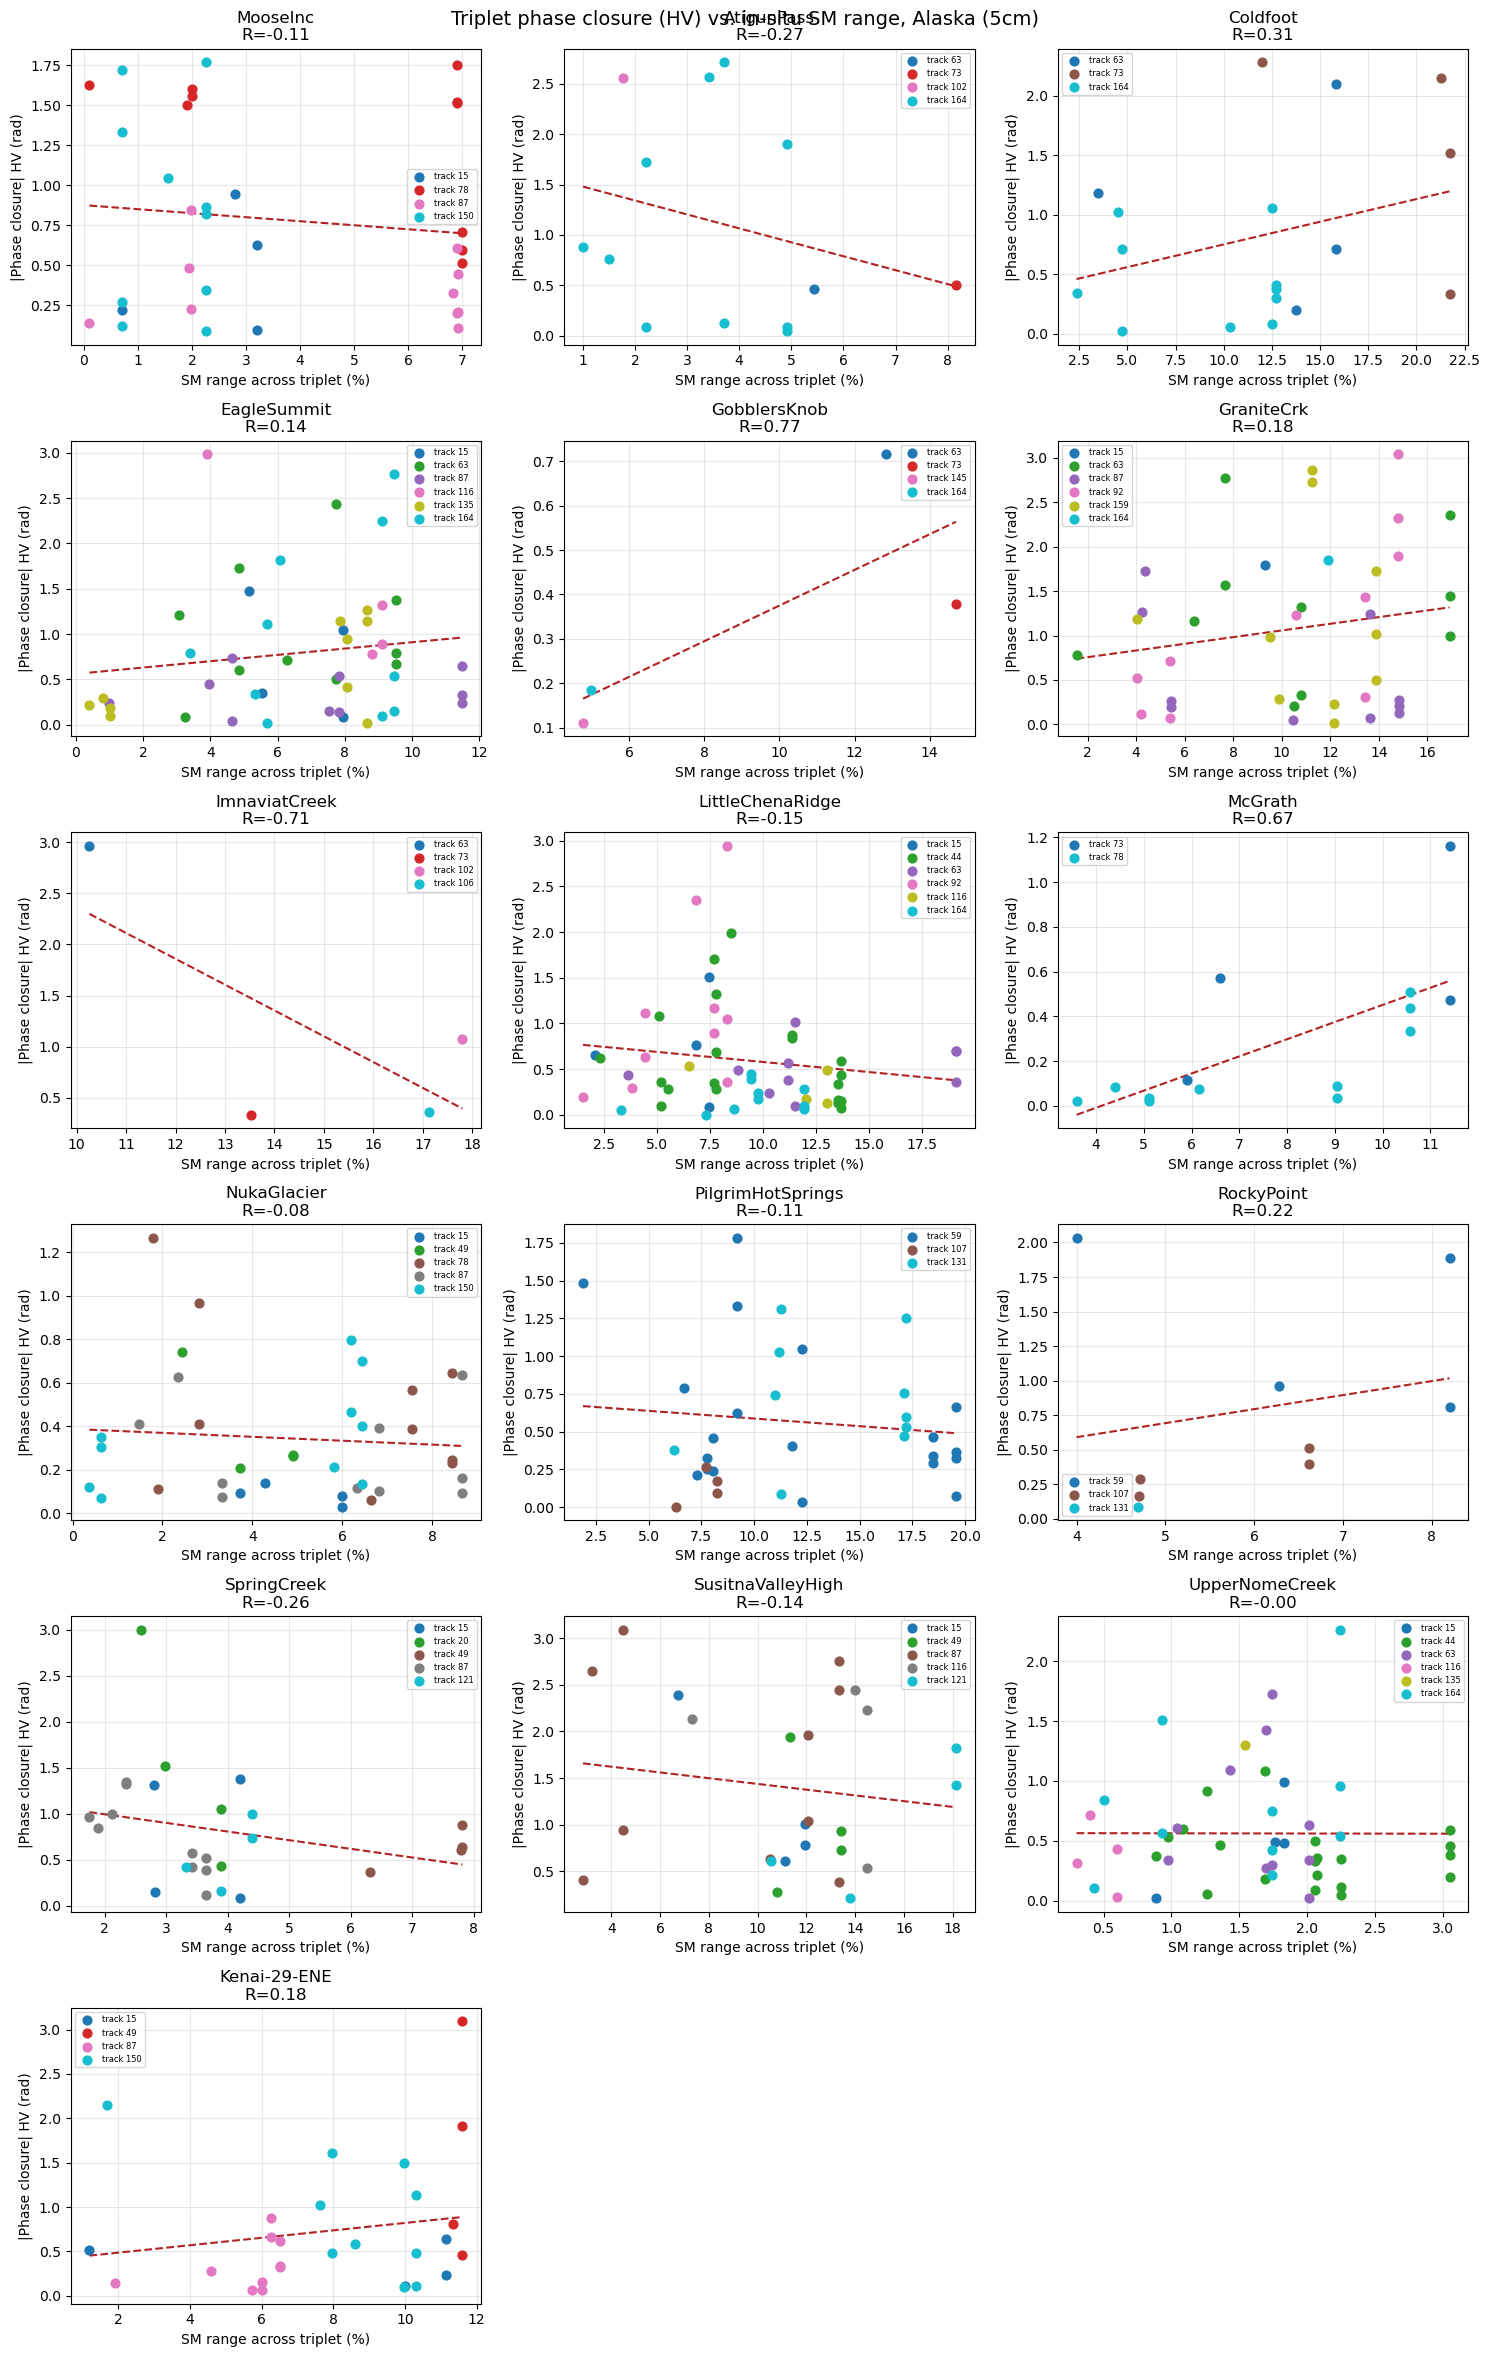

Pearson R (SM range vs |phase closure_HV|) per station, 5cm -- De Zan predicts positive:
  MooseInc: R=-0.113
  AtigunPass: R=-0.265
  Coldfoot: R=0.312
  EagleSummit: R=0.142
  GobblersKnob: R=0.770
  GraniteCrk: R=0.180
  ImnaviatCreek: R=-0.713
  LittleChenaRidge: R=-0.152
  McGrath: R=0.666
  NukaGlacier: R=-0.083
  PilgrimHotSprings: R=-0.114
  RockyPoint: R=0.220
  SpringCreek: R=-0.264
  SusitnaValleyHigh: R=-0.140
  UpperNomeCreek: R=-0.003
  Kenai-29-ENE: R=0.177


In [7]:
require_globals("join_and_compare", "plot_coherence_vs_dsm", "plot_closure_vs_range", "DEPTH_MAIN")

coherence_5cm, closure_5cm = join_and_compare(DEPTH_MAIN)

r_coh_5cm_HH = plot_coherence_vs_dsm(coherence_5cm, "5cm", "HH")
r_coh_5cm_HV = plot_coherence_vs_dsm(coherence_5cm, "5cm", "HV")
r_clo_5cm_HH = plot_closure_vs_range(closure_5cm, "5cm", "HH")
r_clo_5cm_HV = plot_closure_vs_range(closure_5cm, "5cm", "HV")


## 7. 20cm depth (secondary comparison)

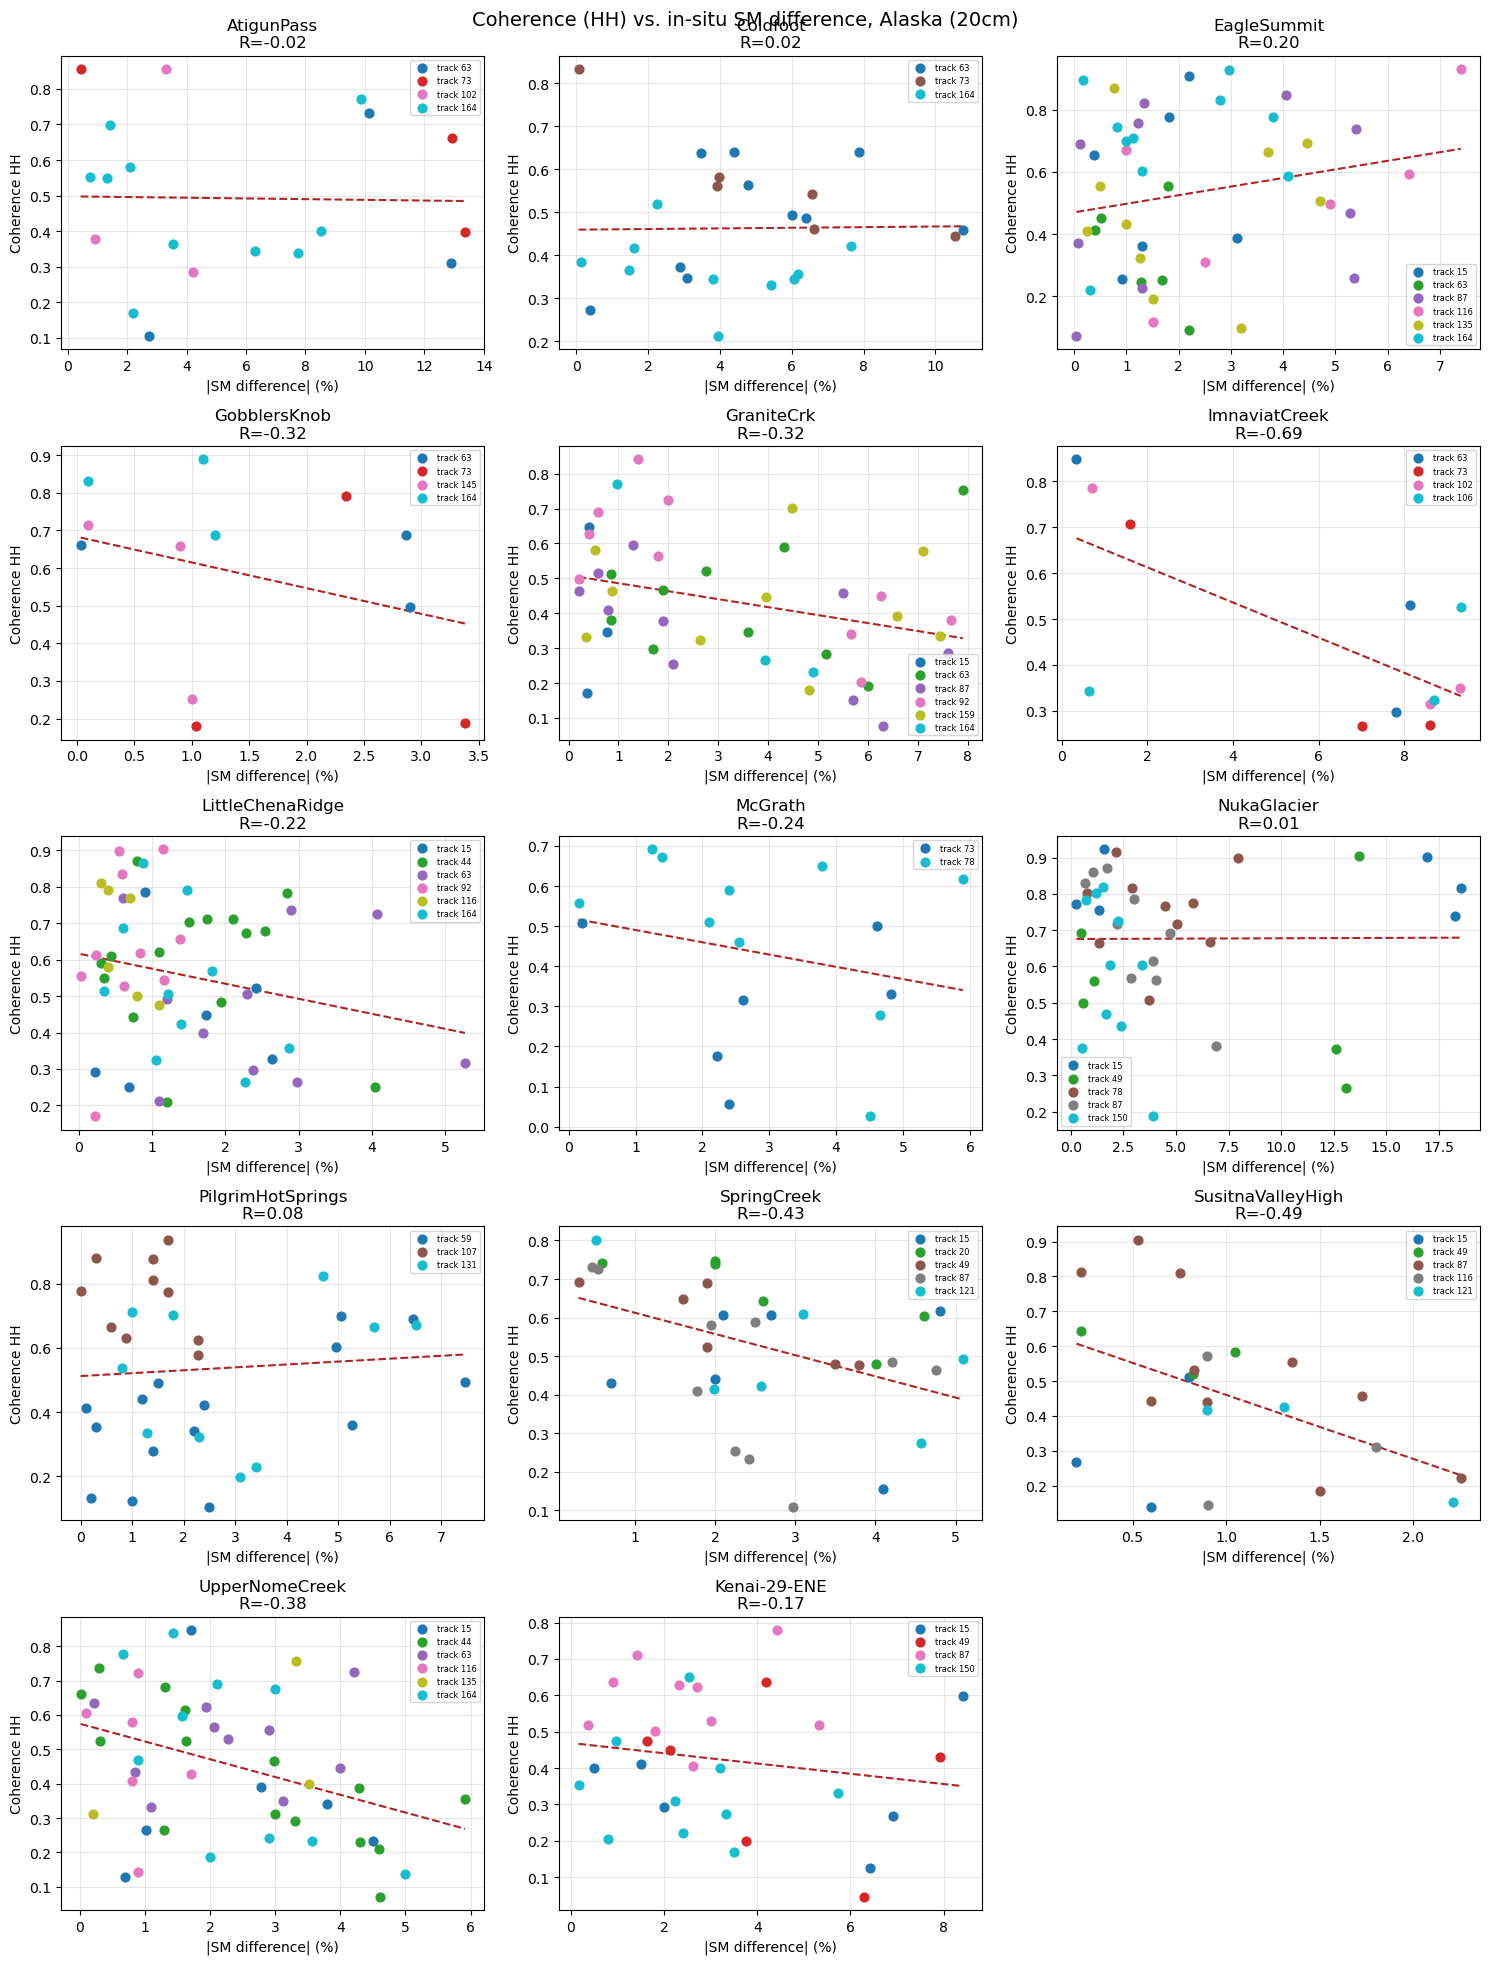

Pearson R (|SM diff| vs coherence_HH) per station, 20cm -- De Zan predicts negative:
  AtigunPass: R=-0.020
  Coldfoot: R=0.015
  EagleSummit: R=0.204
  GobblersKnob: R=-0.321
  GraniteCrk: R=-0.318
  ImnaviatCreek: R=-0.689
  LittleChenaRidge: R=-0.224
  McGrath: R=-0.245
  NukaGlacier: R=0.005
  PilgrimHotSprings: R=0.079
  SpringCreek: R=-0.435
  SusitnaValleyHigh: R=-0.490
  UpperNomeCreek: R=-0.382
  Kenai-29-ENE: R=-0.172


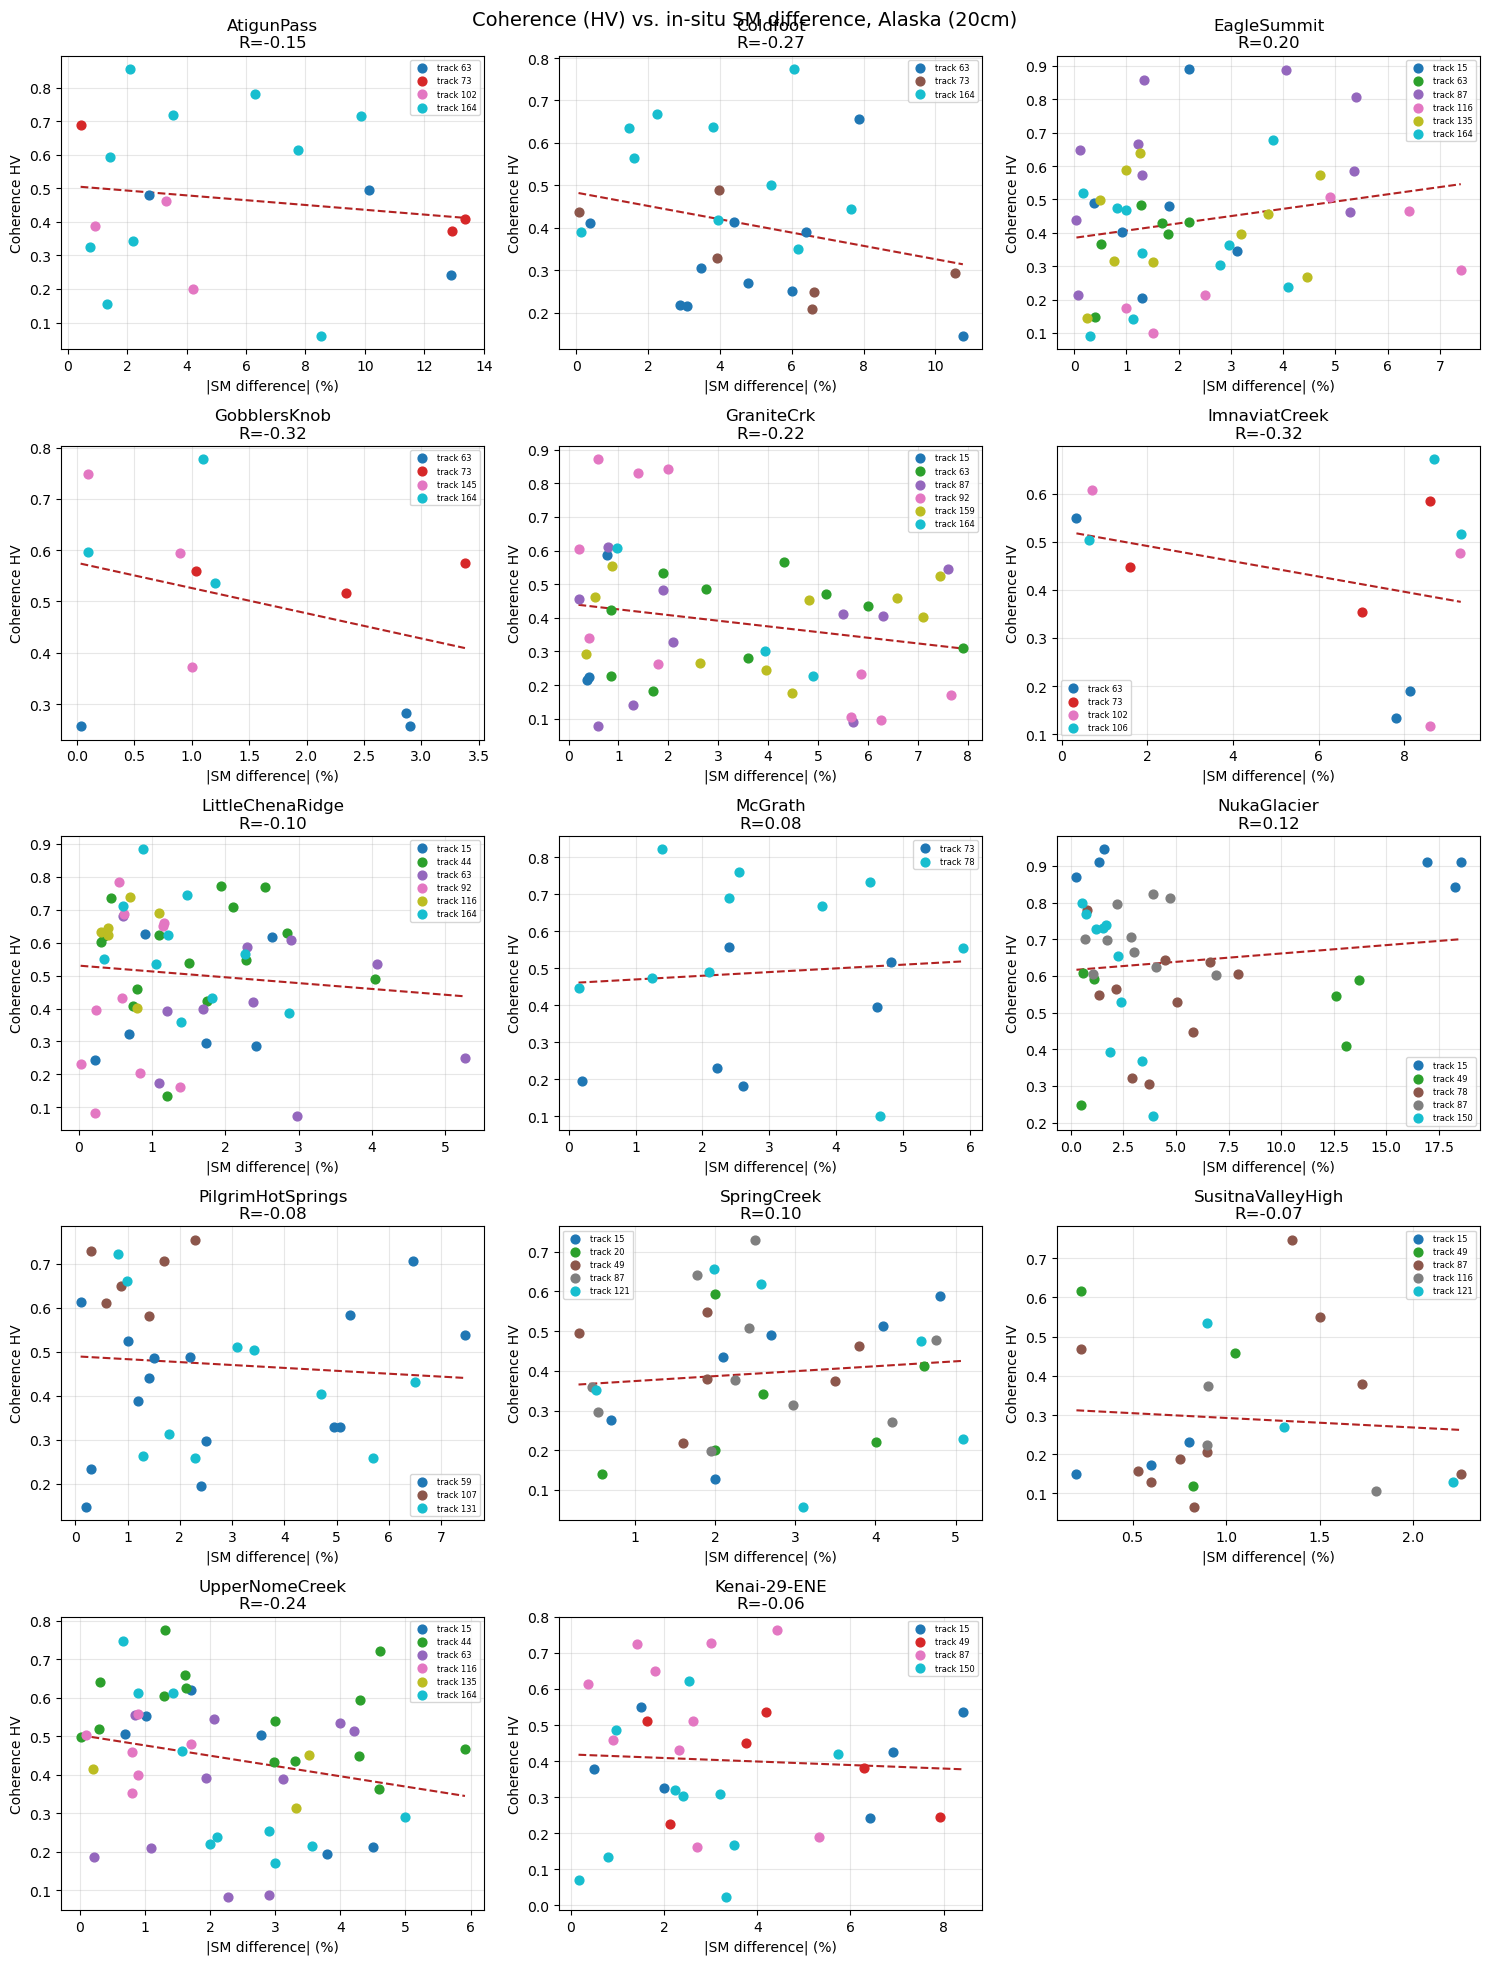

Pearson R (|SM diff| vs coherence_HV) per station, 20cm -- De Zan predicts negative:
  AtigunPass: R=-0.145
  Coldfoot: R=-0.268
  EagleSummit: R=0.201
  GobblersKnob: R=-0.324
  GraniteCrk: R=-0.218
  ImnaviatCreek: R=-0.319
  LittleChenaRidge: R=-0.098
  McGrath: R=0.077
  NukaGlacier: R=0.123
  PilgrimHotSprings: R=-0.079
  SpringCreek: R=0.103
  SusitnaValleyHigh: R=-0.074
  UpperNomeCreek: R=-0.237
  Kenai-29-ENE: R=-0.056


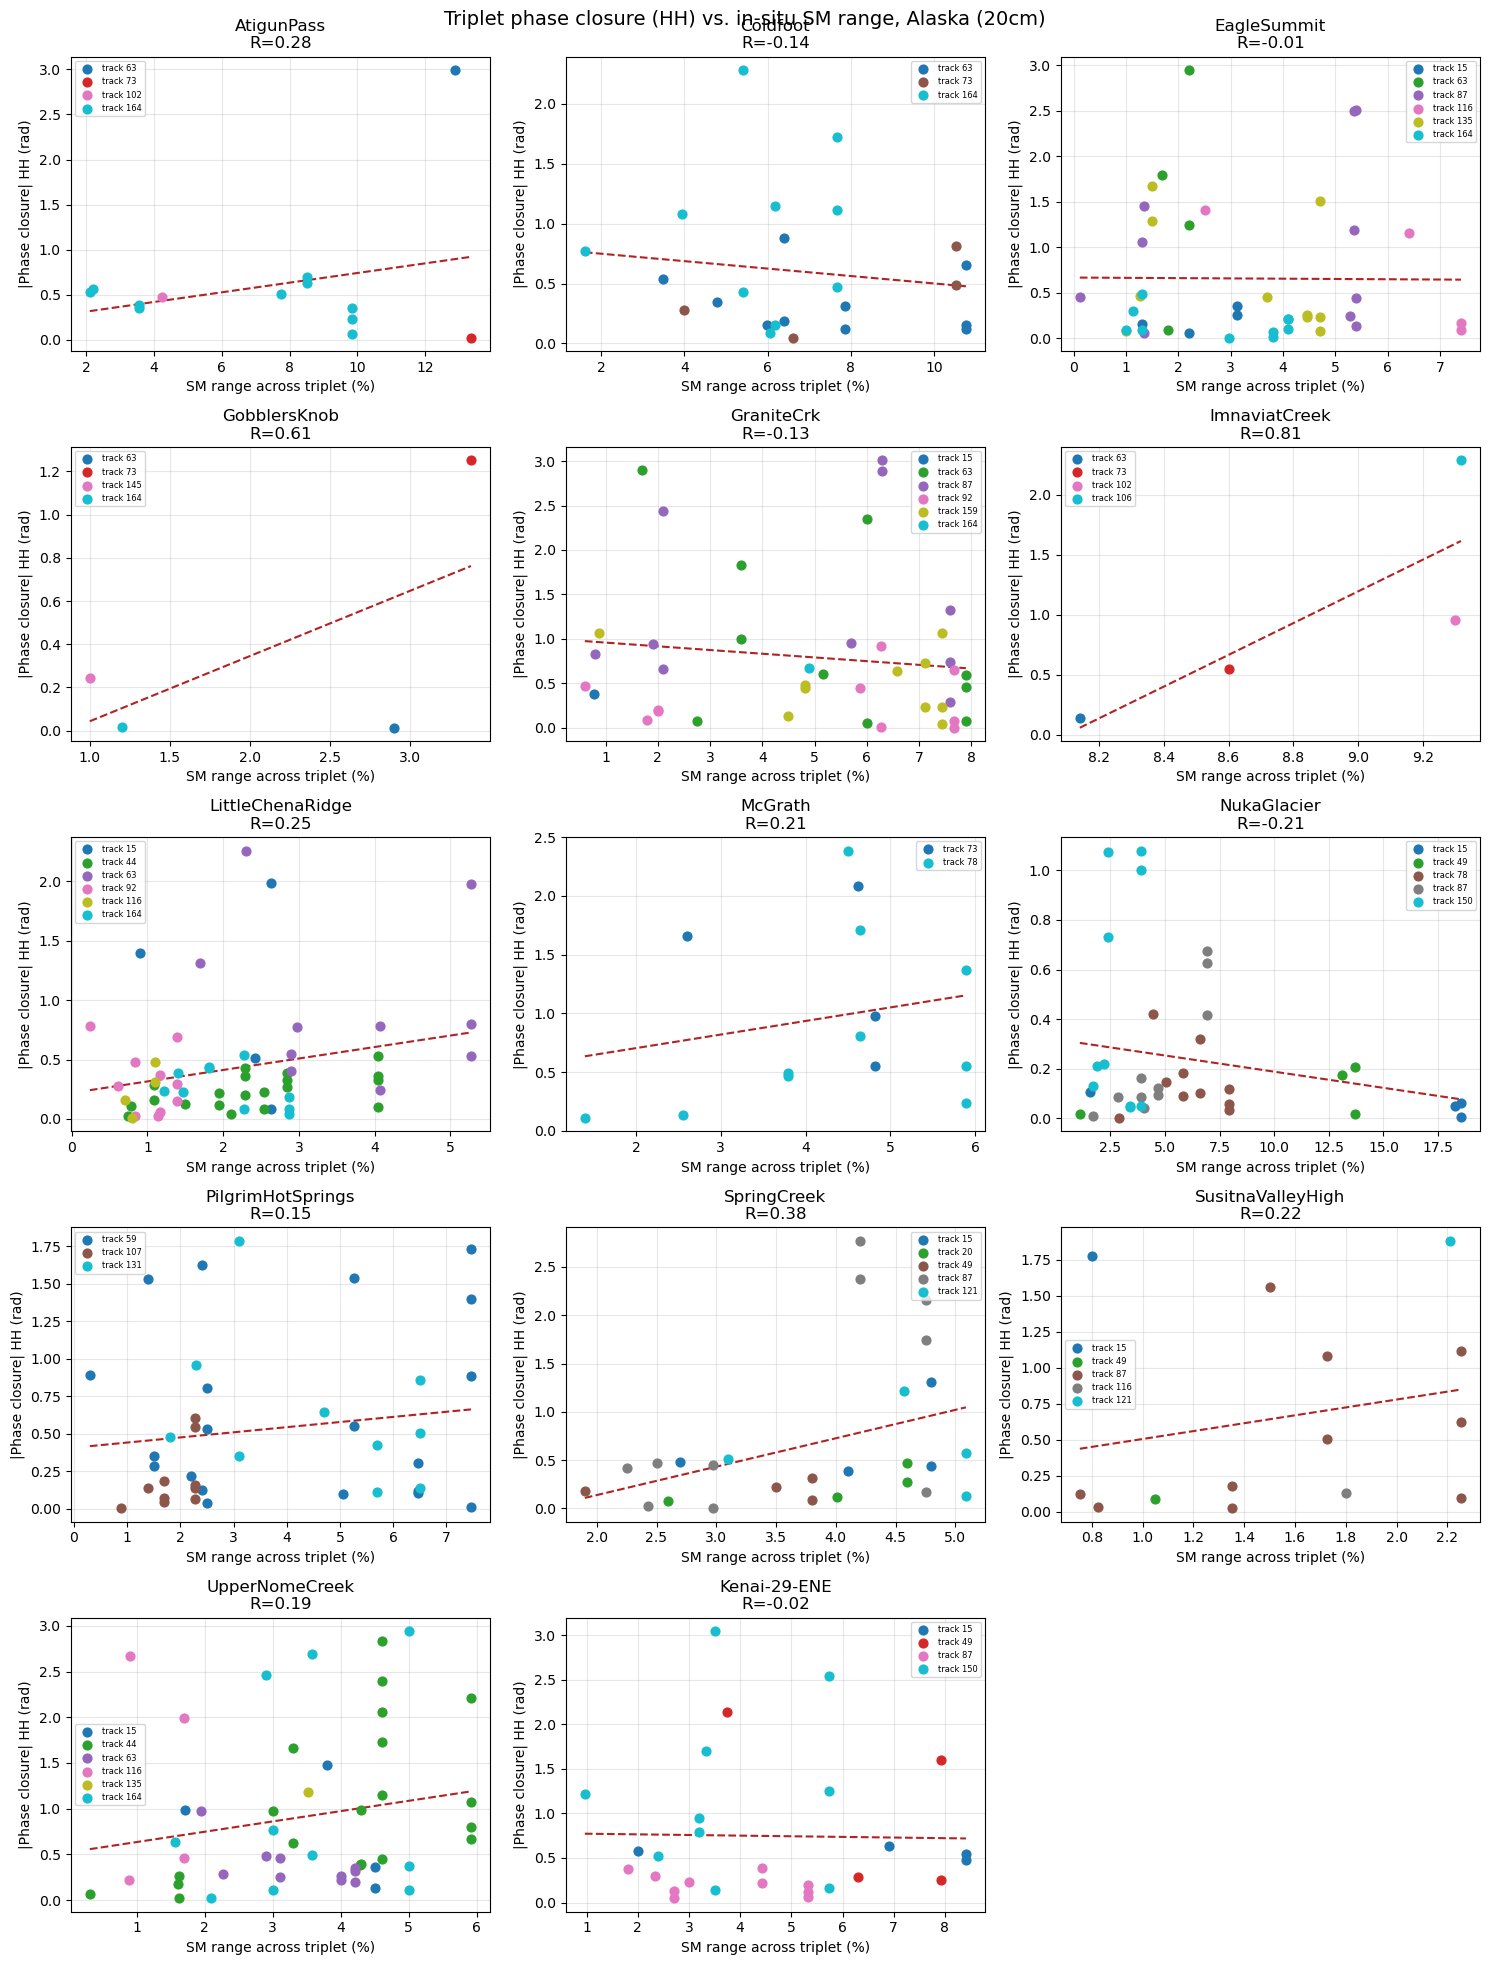

Pearson R (SM range vs |phase closure_HH|) per station, 20cm -- De Zan predicts positive:
  AtigunPass: R=0.279
  Coldfoot: R=-0.139
  EagleSummit: R=-0.008
  GobblersKnob: R=0.612
  GraniteCrk: R=-0.126
  ImnaviatCreek: R=0.814
  LittleChenaRidge: R=0.249
  McGrath: R=0.207
  NukaGlacier: R=-0.207
  PilgrimHotSprings: R=0.145
  SpringCreek: R=0.377
  SusitnaValleyHigh: R=0.223
  UpperNomeCreek: R=0.188
  Kenai-29-ENE: R=-0.019


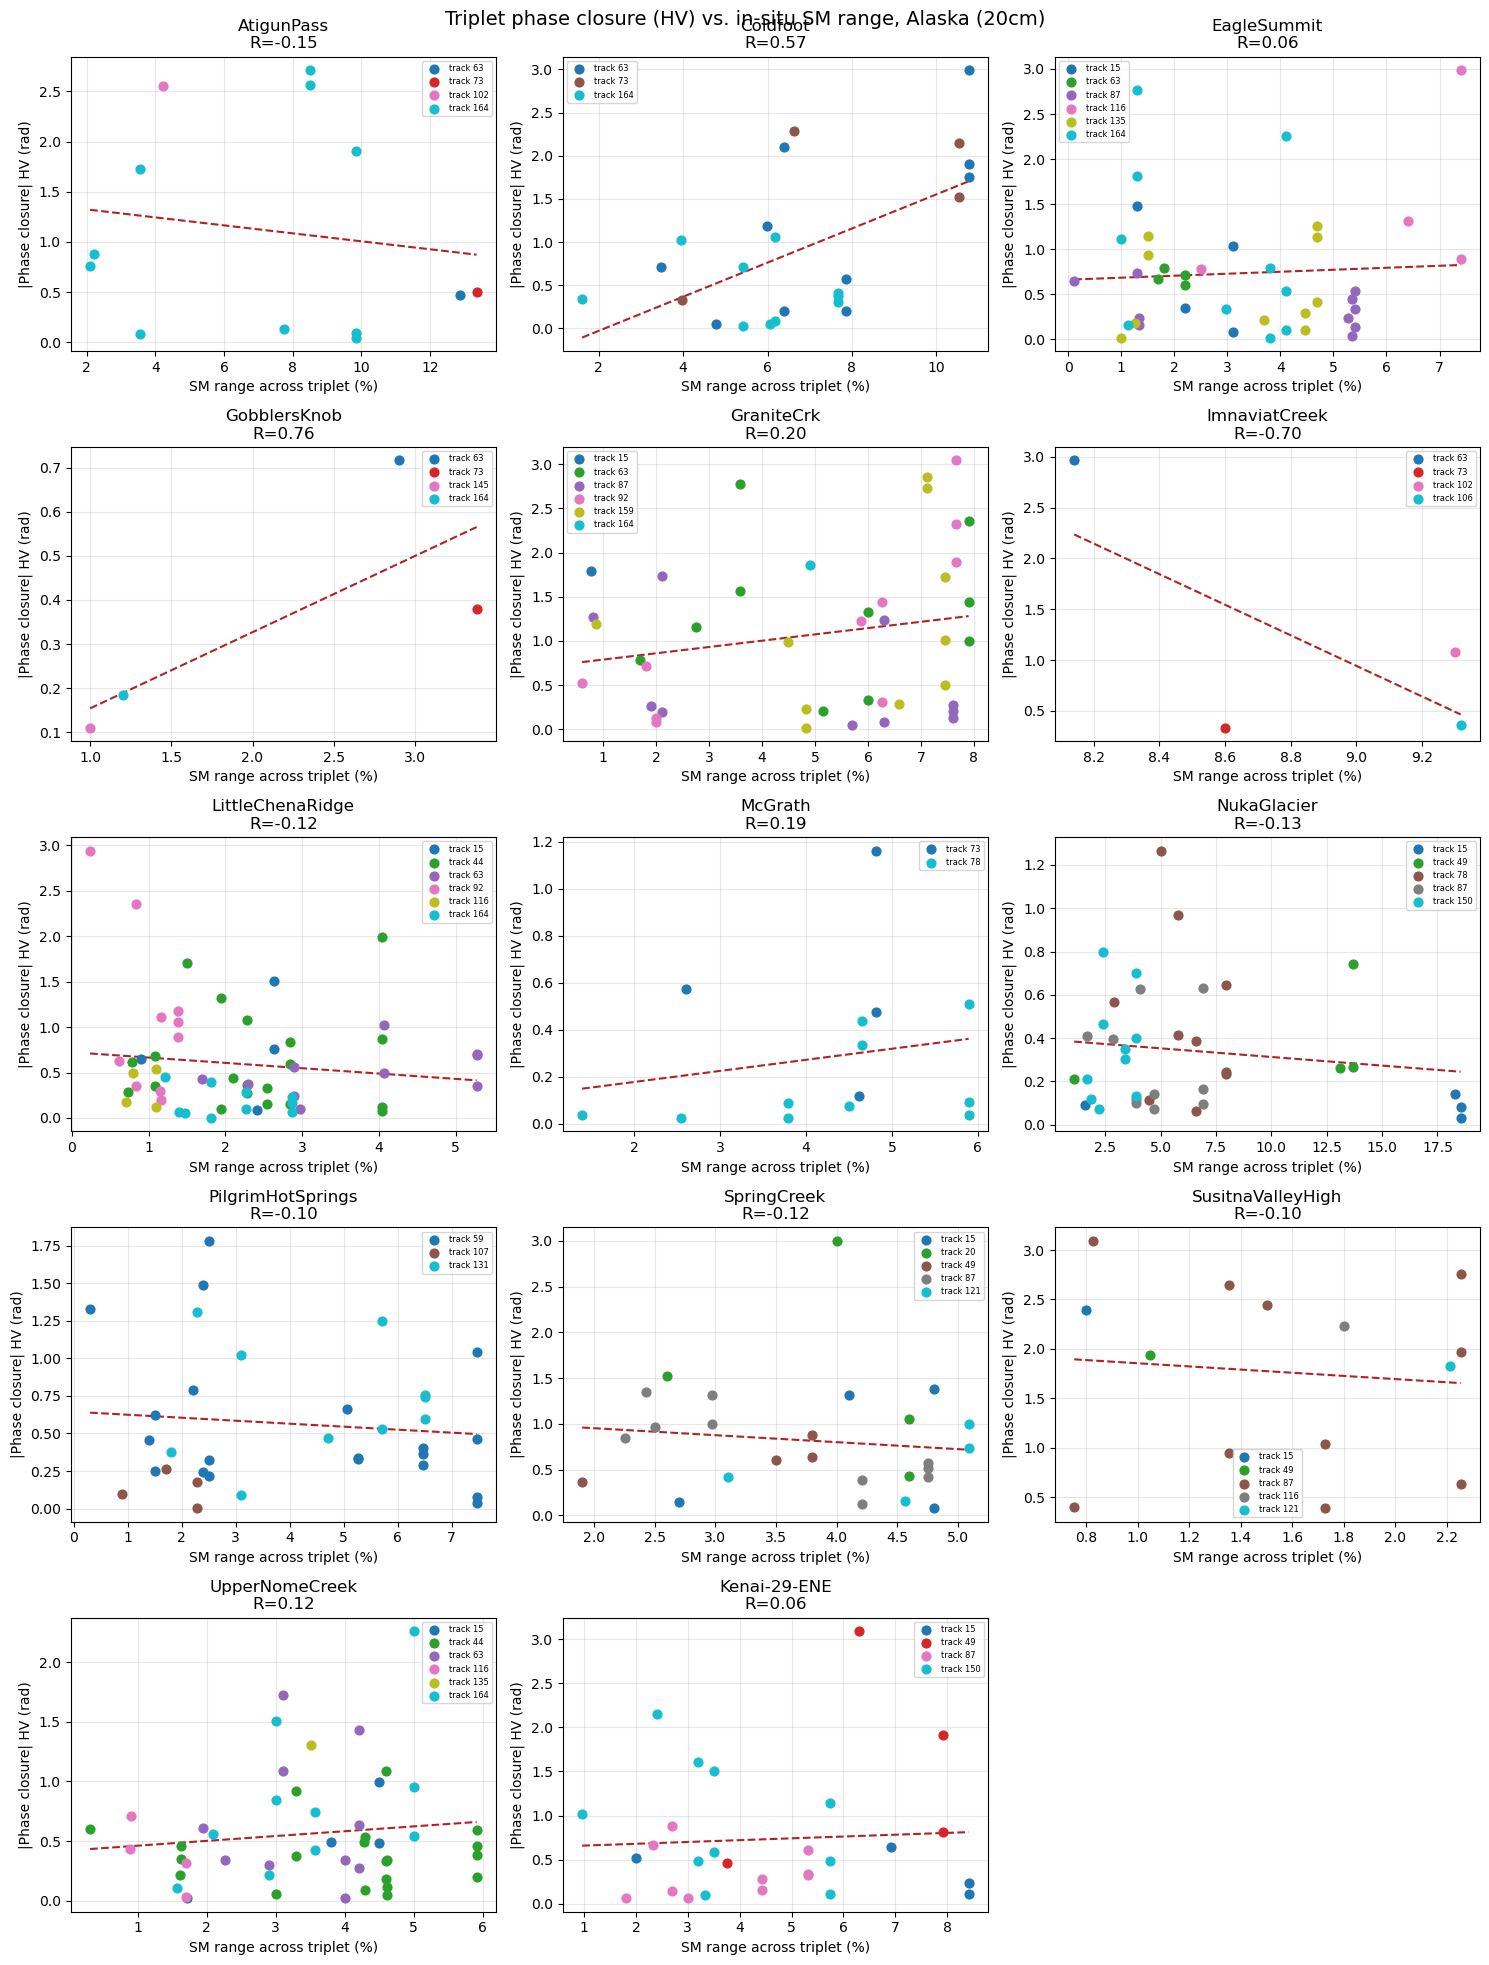

Pearson R (SM range vs |phase closure_HV|) per station, 20cm -- De Zan predicts positive:
  AtigunPass: R=-0.149
  Coldfoot: R=0.574
  EagleSummit: R=0.060
  GobblersKnob: R=0.764
  GraniteCrk: R=0.200
  ImnaviatCreek: R=-0.698
  LittleChenaRidge: R=-0.124
  McGrath: R=0.195
  NukaGlacier: R=-0.134
  PilgrimHotSprings: R=-0.101
  SpringCreek: R=-0.122
  SusitnaValleyHigh: R=-0.098
  UpperNomeCreek: R=0.123
  Kenai-29-ENE: R=0.060


In [8]:
require_globals("join_and_compare", "plot_coherence_vs_dsm", "plot_closure_vs_range", "DEPTH_SECONDARY")

coherence_20cm, closure_20cm = join_and_compare(DEPTH_SECONDARY)

r_coh_20cm_HH = plot_coherence_vs_dsm(coherence_20cm, "20cm", "HH")
r_coh_20cm_HV = plot_coherence_vs_dsm(coherence_20cm, "20cm", "HV")
r_clo_20cm_HH = plot_closure_vs_range(closure_20cm, "20cm", "HH")
r_clo_20cm_HV = plot_closure_vs_range(closure_20cm, "20cm", "HV")


## 8. Overall comparison: every depth x polarization

Pools the 8 (depth, polarization, check) combinations above into one table, so
the best-performing combination is visible directly instead of eyeballed across
4 separate scatter grids. "Best" means matching the De Zan-predicted sign
*and* the largest magnitude: **negative** for coherence vs. |SM difference|,
**positive** for closure phase vs. SM range -- a station where De Zan's
prediction fails outright will show the wrong sign here, not just a weak R.

=== Coherence vs. |SM difference| (De Zan predicts negative R) ===


,depth,pol,n_stations,mean_R,median_R,n_correct_sign,frac_correct_sign
0,5cm,HH,16,-0.213893,-0.253672,12,0.750000
1,20cm,HH,14,-0.213736,-0.234547,10,0.714286
2,5cm,HV,16,-0.173960,-0.170413,15,0.937500
3,20cm,HV,14,-0.093902,-0.088278,10,0.714286



=== Closure phase vs. SM range (De Zan predicts positive R) ===


,depth,pol,n_stations,mean_R,median_R,n_correct_sign,frac_correct_sign
0,20cm,HH,14,0.185417,0.197883,9,0.642857
1,5cm,HH,16,0.158760,0.104611,12,0.750000
2,20cm,HV,14,0.039210,-0.019246,7,0.500000
3,5cm,HV,16,0.038888,-0.042598,7,0.437500



Best coherence combo: 5cm HH (mean R=-0.214, 12/16 station(s) negative)
Best closure combo: 20cm HH (mean R=0.185, 9/14 station(s) positive)


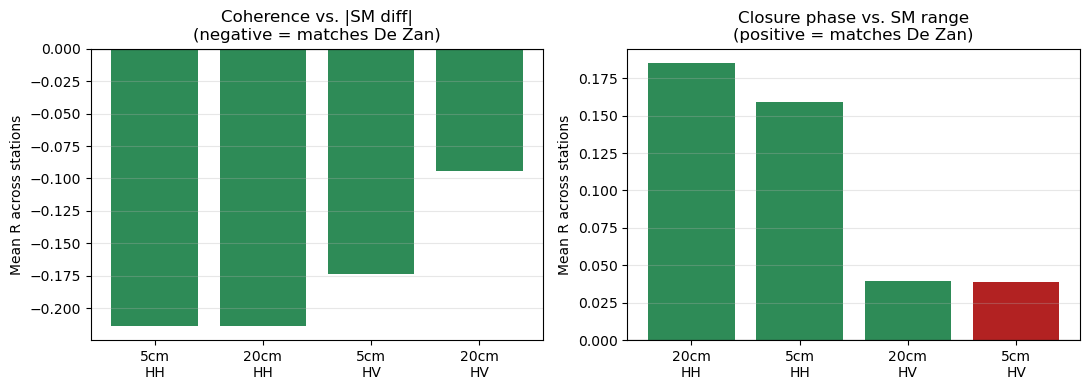

In [9]:
require_globals(
    "r_coh_5cm_HH", "r_coh_5cm_HV", "r_coh_20cm_HH", "r_coh_20cm_HV",
    "r_clo_5cm_HH", "r_clo_5cm_HV", "r_clo_20cm_HH", "r_clo_20cm_HV",
)

coherence_results = {
    ("5cm", "HH"): r_coh_5cm_HH, ("5cm", "HV"): r_coh_5cm_HV,
    ("20cm", "HH"): r_coh_20cm_HH, ("20cm", "HV"): r_coh_20cm_HV,
}
closure_results = {
    ("5cm", "HH"): r_clo_5cm_HH, ("5cm", "HV"): r_clo_5cm_HV,
    ("20cm", "HH"): r_clo_20cm_HH, ("20cm", "HV"): r_clo_20cm_HV,
}


def summarize(results_by_combo, expected_sign):
    """results_by_combo: {(depth, pol): {station: R}}. One row per (depth, pol):
    mean/median R across stations with a usable R, and how many of those match
    De Zan's predicted sign. Sorted best-first (most negative mean_R for
    expected_sign=-1, most positive for expected_sign=+1)."""
    rows = []
    for (depth, pol), r_by_station in results_by_combo.items():
        r_values = np.array([r for r in r_by_station.values() if not np.isnan(r)])
        n_valid = len(r_values)
        n_correct_sign = int(np.sum(r_values * expected_sign > 0))
        rows.append({
            "depth": depth, "pol": pol,
            "n_stations": n_valid,
            "mean_R": r_values.mean() if n_valid else np.nan,
            "median_R": np.median(r_values) if n_valid else np.nan,
            "n_correct_sign": n_correct_sign,
            "frac_correct_sign": n_correct_sign / n_valid if n_valid else np.nan,
        })
    df = pd.DataFrame(rows)
    ascending = expected_sign < 0  # most-negative-first for coherence, most-positive-first for closure
    return df.sort_values("mean_R", ascending=ascending).reset_index(drop=True)


print("=== Coherence vs. |SM difference| (De Zan predicts negative R) ===")
coherence_summary = summarize(coherence_results, expected_sign=-1)
display(coherence_summary)

print("\n=== Closure phase vs. SM range (De Zan predicts positive R) ===")
closure_summary = summarize(closure_results, expected_sign=+1)
display(closure_summary)

best_coh = coherence_summary.iloc[0]
best_clo = closure_summary.iloc[0]
print(f"\nBest coherence combo: {best_coh['depth']} {best_coh['pol']} "
      f"(mean R={best_coh['mean_R']:.3f}, {best_coh['n_correct_sign']}/{best_coh['n_stations']} station(s) negative)")
print(f"Best closure combo: {best_clo['depth']} {best_clo['pol']} "
      f"(mean R={best_clo['mean_R']:.3f}, {best_clo['n_correct_sign']}/{best_clo['n_stations']} station(s) positive)")

fig, (ax_coh, ax_clo) = plt.subplots(1, 2, figsize=(11, 4))
for ax, summary, title in (
    (ax_coh, coherence_summary, "Coherence vs. |SM diff|\n(negative = matches De Zan)"),
    (ax_clo, closure_summary, "Closure phase vs. SM range\n(positive = matches De Zan)"),
):
    labels = [f"{row.depth}\n{row.pol}" for row in summary.itertuples()]
    colors = ["seagreen" if c else "firebrick" for c in summary["n_correct_sign"] >= summary["n_stations"] / 2]
    ax.bar(labels, summary["mean_R"], color=colors)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_ylabel("Mean R across stations")
    ax.set_title(title)
    ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


## 9. NDVI vs. coherence

Vegetation canopy structure change between two acquisitions is a well known
secondary source of InSAR temporal decorrelation, independent of the De Zan
soil-moisture mechanism checked above. Reads
`alaska_HLS_ndvi/{station}_HLS_ndvi.csv` (written by
[`05_get_HLS_ndvi.ipynb`](Earsel26_NISAR-main/notebooks/05_get_HLS_ndvi.ipynb),
HLS Landsat/Sentinel-2 NDVI sampled at each station's own NISAR acquisition
dates -- `target_date` there is built from the exact same acquisition list
this notebook's own `date_1`/`date_2` come from, so the join below is an exact
timestamp match, no interpolation needed) and, mirroring this notebook's own
`|SM difference|` vs. coherence design (Sections 4-6), computes
`dndvi = |NDVI(date_1) - NDVI(date_2)|` per coherence pair and correlates it
against `coherence_<pol>`: more vegetation change between two acquisitions is
expected to mean **more** decorrelation, i.e. a **negative** R -- same sign
convention as the SM check.

**Coverage caveat**: most rows in `alaska_HLS_ndvi/` have `n_valid_px=0`
(fully cloud/shadow/snow-masked at this 80x80m window for that date) --
`read_ndvi` drops those, so usable pair counts per station are often much
smaller than the coherence table's own row count; a station left with too few
usable pairs shows `R=nan`, not a real zero-correlation result. Independent of
depth (NDVI isn't a soil-moisture-depth quantity), so this runs once, not
once per depth like Sections 6/7.

In [10]:
require_globals("coherence_by_station", "MIN_BASELINE_DAYS", "EARSEL_NOTEBOOKS")

NDVI_DIR = EARSEL_NOTEBOOKS / "nisar_data" / "alaska_HLS_ndvi"


def read_ndvi(station):
    path = NDVI_DIR / f"{station}_HLS_ndvi.csv"
    if not path.exists():
        return None
    df = pd.read_csv(path, parse_dates=["target_date"])
    df = df[df["n_valid_px"] > 0]
    if df.empty:
        return None
    return df.set_index("target_date")["ndvi_mean"].sort_index()


ndvi_dfs = {}
for station, df_coh in coherence_by_station.items():
    ndvi_series = read_ndvi(station)
    if ndvi_series is None:
        continue
    df = df_coh[df_coh["temporal_baseline_days"] >= MIN_BASELINE_DAYS].copy()
    df["ndvi_1"] = df["date_1"].map(ndvi_series)
    df["ndvi_2"] = df["date_2"].map(ndvi_series)
    df["dndvi"] = (df["ndvi_1"] - df["ndvi_2"]).abs()
    ndvi_dfs[station] = df

print(f"{len(ndvi_dfs)}/{len(coherence_by_station)} station(s) have usable NDVI data")
for station, df in ndvi_dfs.items():
    n_usable = df["dndvi"].notna().sum()
    print(f"  {station}: {n_usable}/{len(df)} pair(s) with both dates' NDVI available")


15/17 station(s) have usable NDVI data
  Coldfoot: 11/36 pair(s) with both dates' NDVI available
  EagleSummit: 0/52 pair(s) with both dates' NDVI available
  GobblersKnob: 1/36 pair(s) with both dates' NDVI available
  GraniteCrk: 3/49 pair(s) with both dates' NDVI available
  ImnaviatCreek: 0/28 pair(s) with both dates' NDVI available
  LittleChenaRidge: 1/57 pair(s) with both dates' NDVI available
  McGrath: 1/31 pair(s) with both dates' NDVI available
  NukaGlacier: 12/52 pair(s) with both dates' NDVI available
  PilgrimHotSprings: 3/65 pair(s) with both dates' NDVI available
  RockyPoint: 1/41 pair(s) with both dates' NDVI available
  SpringCreek: 13/34 pair(s) with both dates' NDVI available
  SusitnaValleyHigh: 1/40 pair(s) with both dates' NDVI available
  TurnagainPass: 4/38 pair(s) with both dates' NDVI available
  UpperNomeCreek: 0/57 pair(s) with both dates' NDVI available
  Kenai-29-ENE: 2/32 pair(s) with both dates' NDVI available


C:\Users\geoka\AppData\Local\Temp\ipykernel_8604\2783516288.py:37: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=6, loc="best")


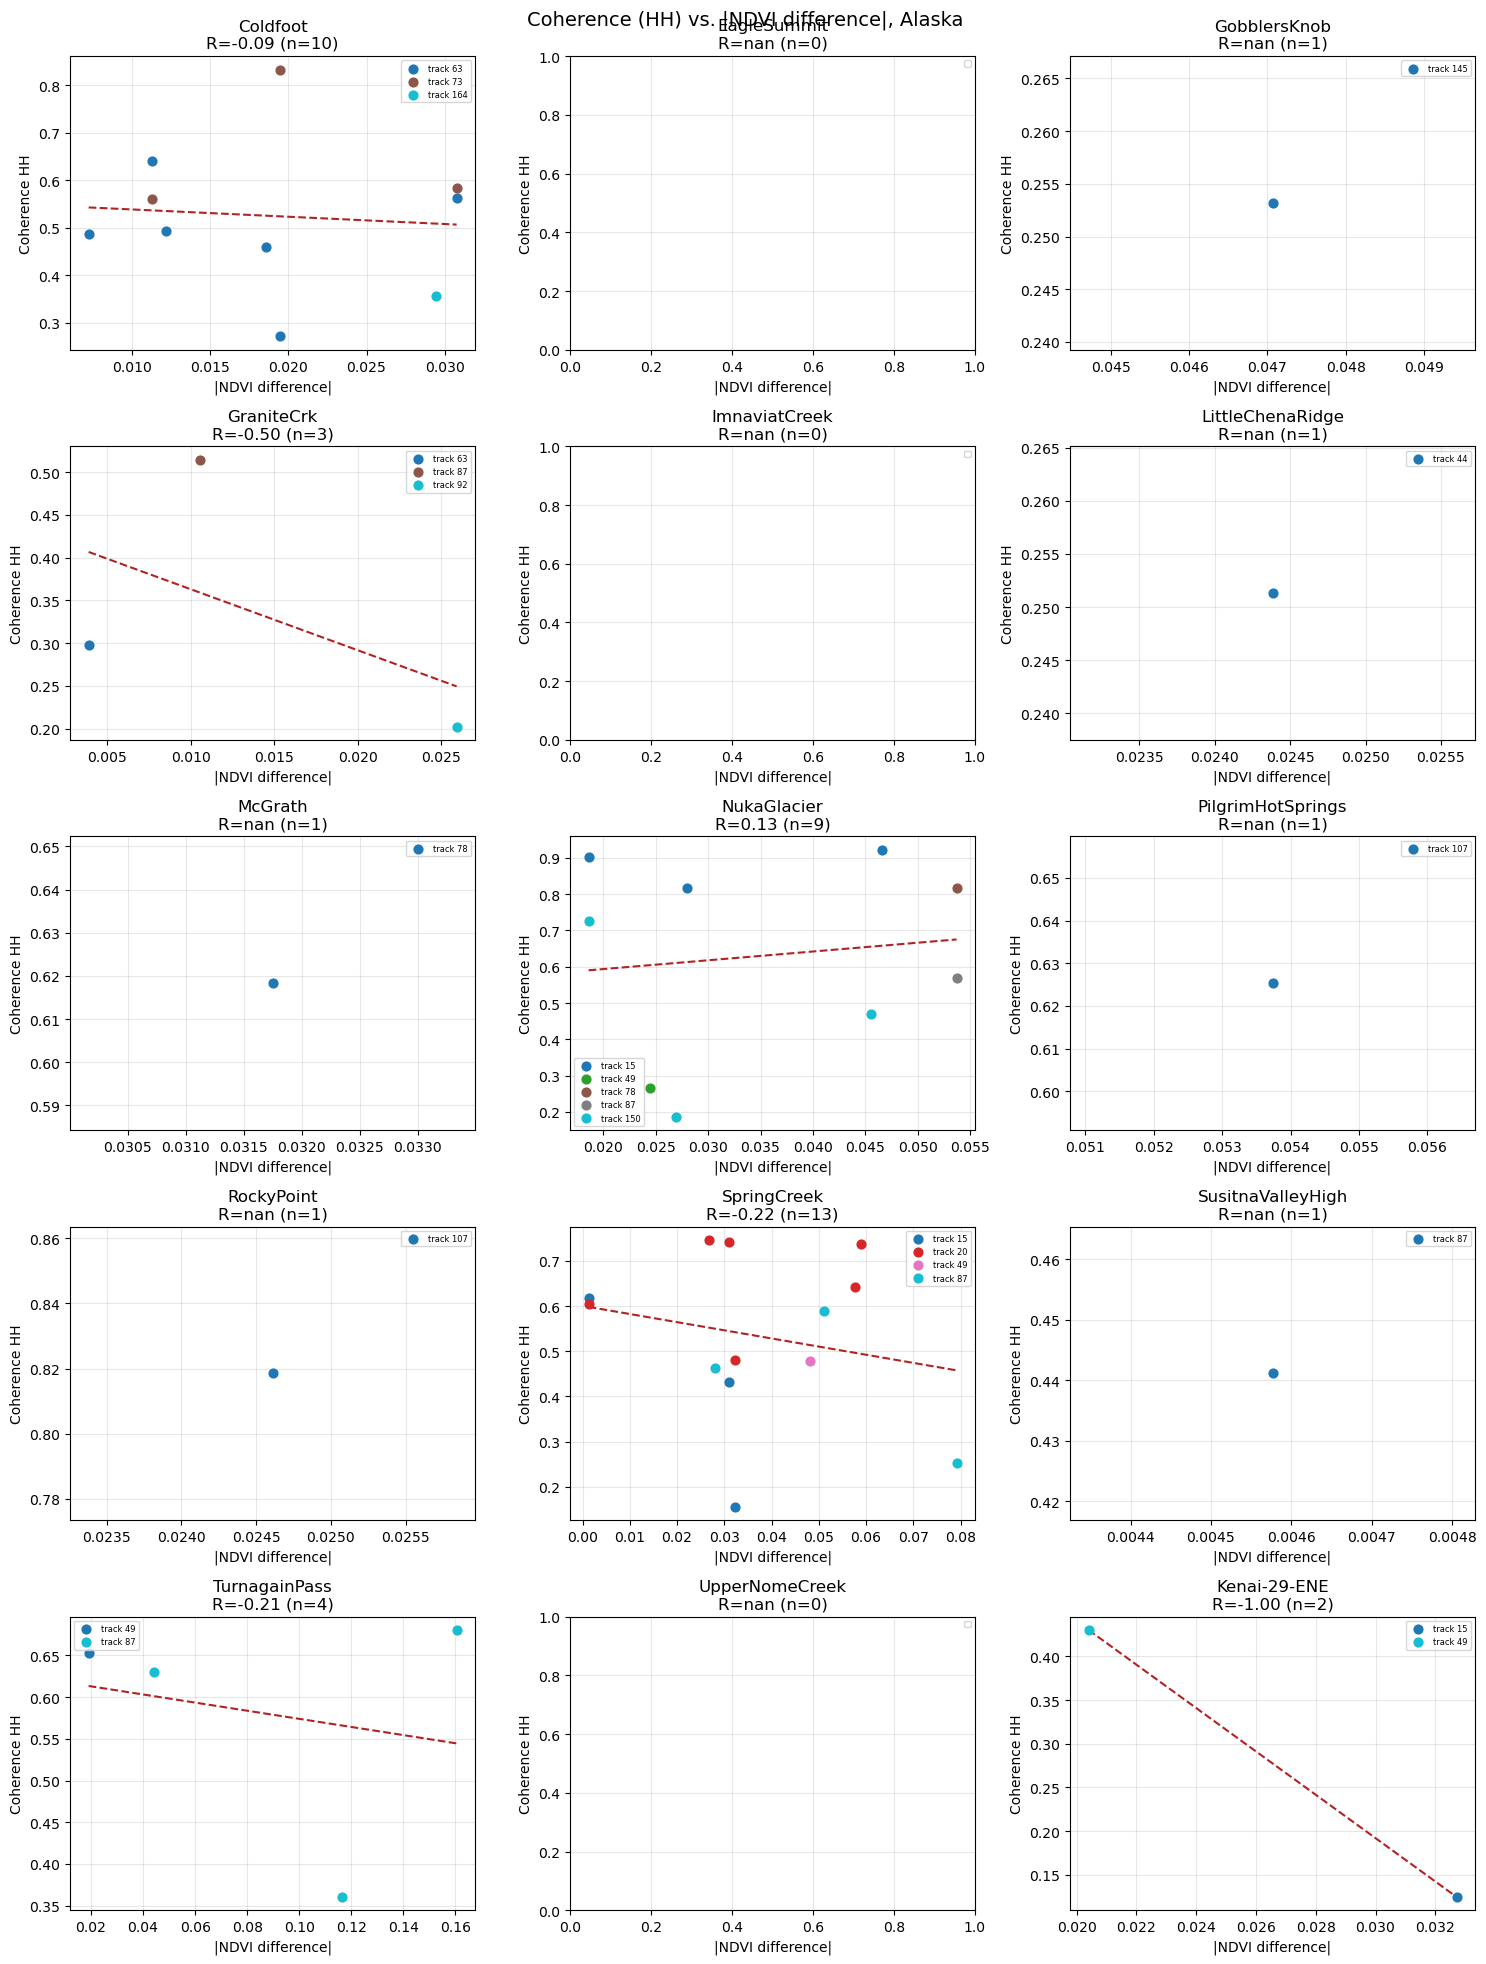

Pearson R (|NDVI diff| vs coherence_HH) per station -- more vegetation change should mean more decorrelation, predicts negative:
  Coldfoot: R=-0.087
  EagleSummit: R=nan
  GobblersKnob: R=nan
  GraniteCrk: R=-0.504
  ImnaviatCreek: R=nan
  LittleChenaRidge: R=nan
  McGrath: R=nan
  NukaGlacier: R=0.130
  PilgrimHotSprings: R=nan
  RockyPoint: R=nan
  SpringCreek: R=-0.218
  SusitnaValleyHigh: R=nan
  TurnagainPass: R=-0.213
  UpperNomeCreek: R=nan
  Kenai-29-ENE: R=-1.000


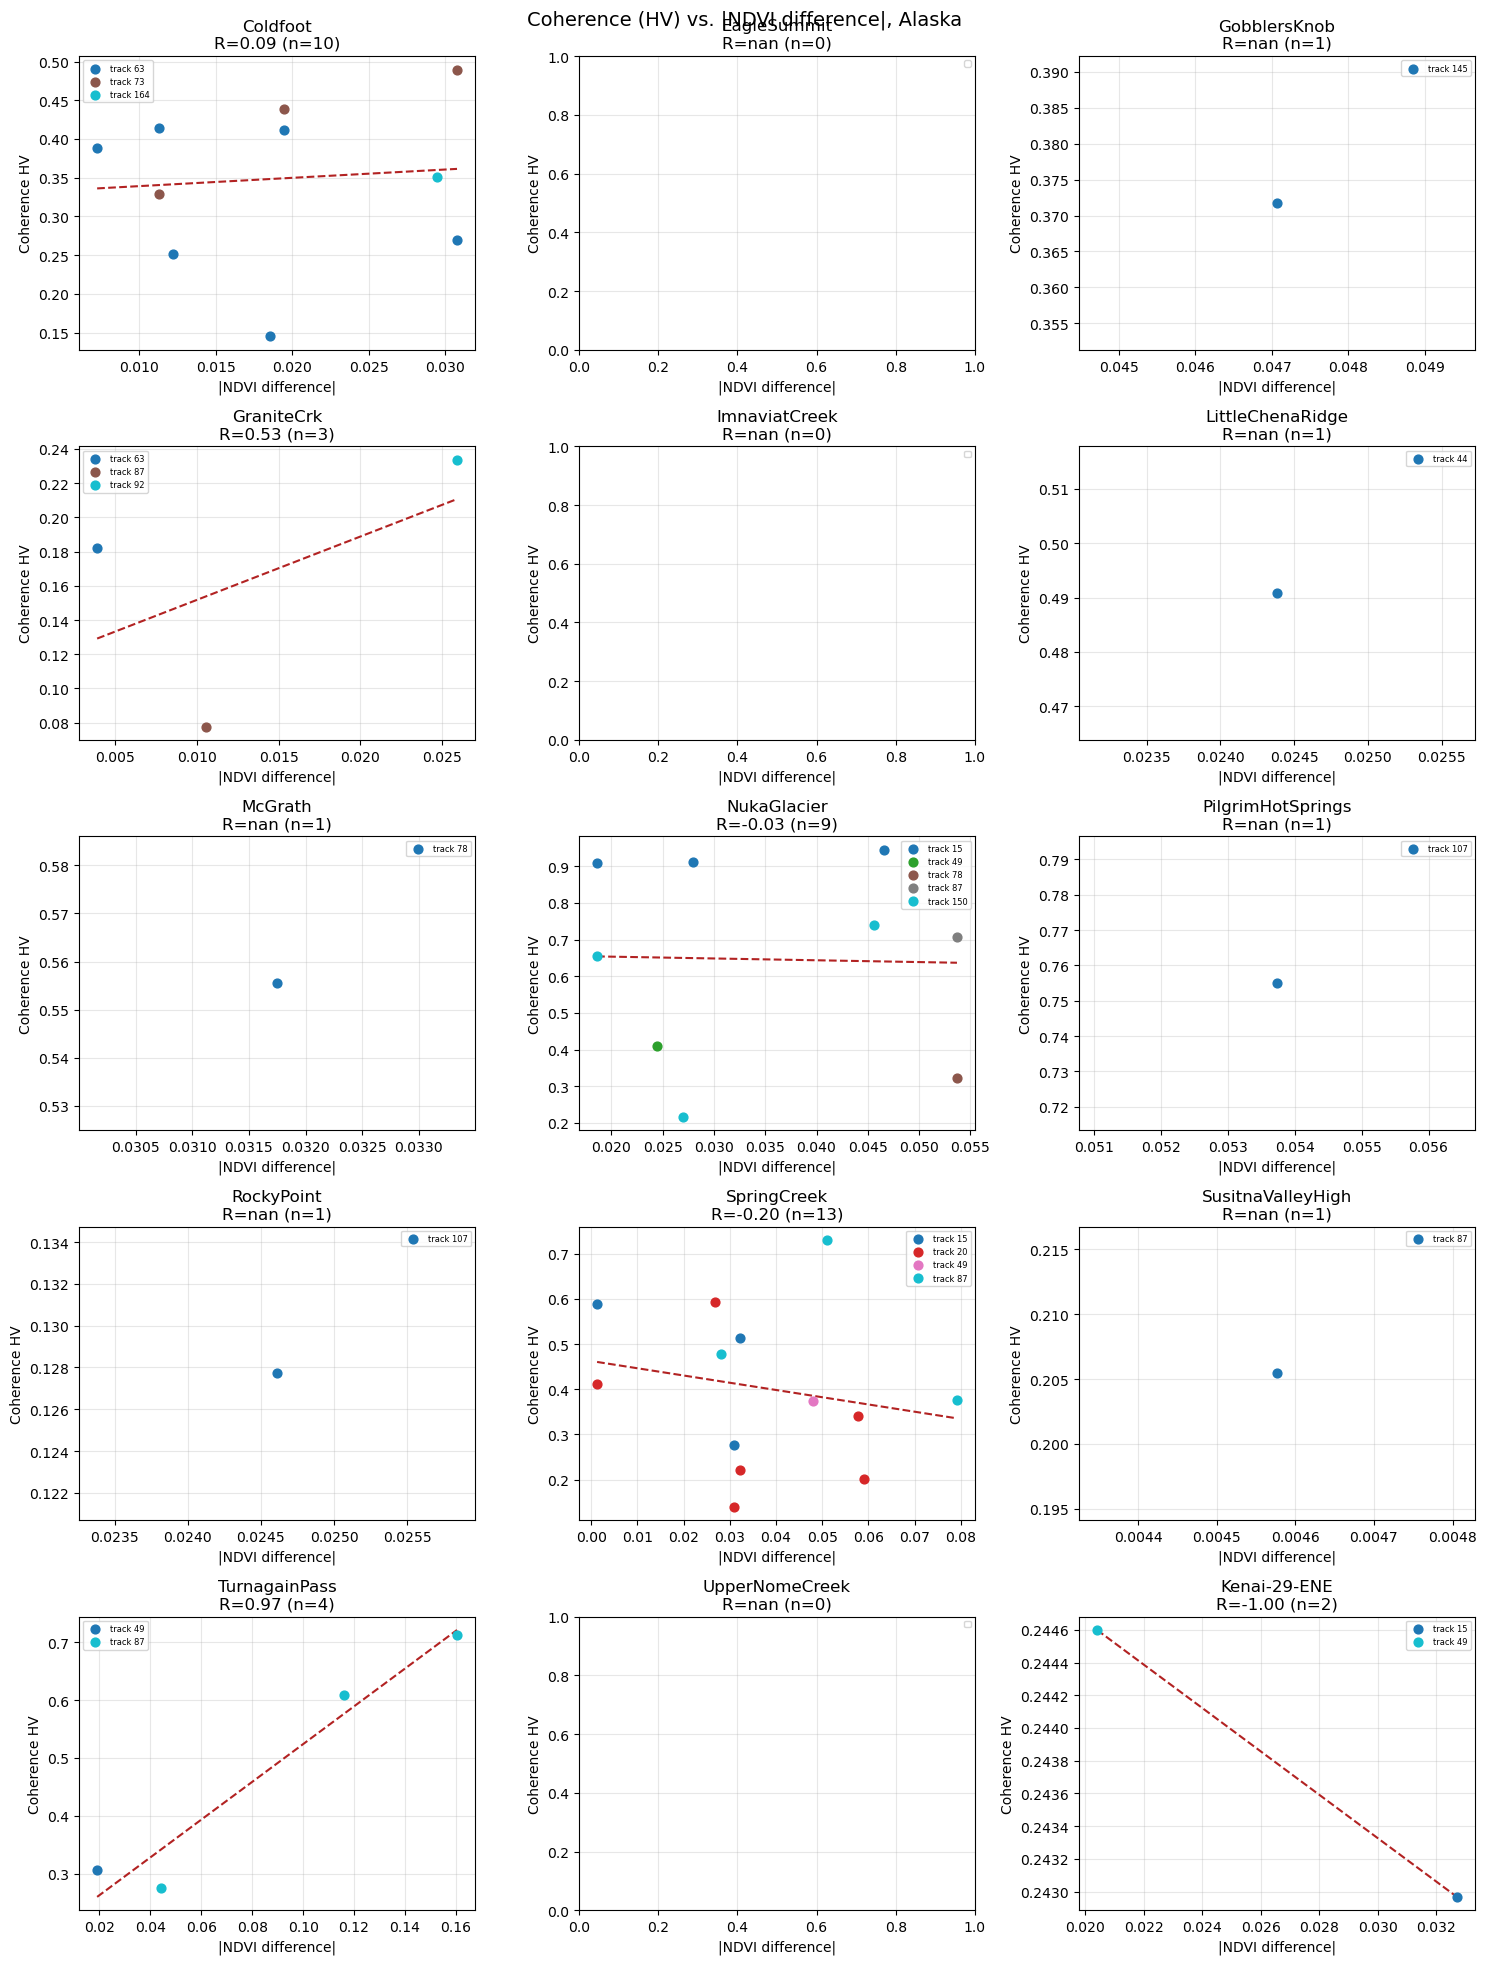

Pearson R (|NDVI diff| vs coherence_HV) per station -- more vegetation change should mean more decorrelation, predicts negative:
  Coldfoot: R=0.091
  EagleSummit: R=nan
  GobblersKnob: R=nan
  GraniteCrk: R=0.526
  ImnaviatCreek: R=nan
  LittleChenaRidge: R=nan
  McGrath: R=nan
  NukaGlacier: R=-0.027
  PilgrimHotSprings: R=nan
  RockyPoint: R=nan
  SpringCreek: R=-0.204
  SusitnaValleyHigh: R=nan
  TurnagainPass: R=0.973
  UpperNomeCreek: R=nan
  Kenai-29-ENE: R=-1.000


In [11]:
require_globals("ndvi_dfs")


def plot_coherence_vs_dndvi(ndvi_dfs, pol):
    coh_col = f"coherence_{pol}"
    station_list = list(ndvi_dfs.keys())
    n_stations = len(station_list)
    ncols = 3
    nrows = int((n_stations + ncols - 1) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 5, nrows * 4))
    axes = axes.flatten()

    r_by_station = {}
    for idx, station in enumerate(station_list):
        ax = axes[idx]
        df_v = ndvi_dfs[station]
        valid = df_v[coh_col].notna() & df_v["dndvi"].notna()
        df_v = df_v.loc[valid]
        x = df_v["dndvi"].values
        y = df_v[coh_col].values
        r = np.corrcoef(x, y)[0, 1] if len(x) > 1 else np.nan
        r_by_station[station] = r

        orbits = sorted(df_v["orbit_num"].unique())
        colors = cm.tab10(np.linspace(0, 1, max(len(orbits), 1)))
        for orbit, color in zip(orbits, colors):
            m = df_v["orbit_num"] == orbit
            ax.scatter(df_v.loc[m, "dndvi"], df_v.loc[m, coh_col], color=color, s=40,
                       label=f"track {orbit}", zorder=3)
        if len(x) > 1:
            fit = np.polyfit(x, y, 1)
            xs = np.linspace(x.min(), x.max(), 10)
            ax.plot(xs, np.polyval(fit, xs), "--", color="firebrick", linewidth=1.5)
        ax.set_title(f"{station}\nR={r:.2f} (n={len(x)})")
        ax.set_xlabel("|NDVI difference|")
        ax.set_ylabel(f"Coherence {pol}")
        ax.legend(fontsize=6, loc="best")
        ax.grid(True, alpha=0.3)

    for idx in range(n_stations, len(axes)):
        axes[idx].axis("off")

    plt.suptitle(f"Coherence ({pol}) vs. |NDVI difference|, Alaska", fontsize=14)
    plt.tight_layout()
    plt.show()

    print(f"Pearson R (|NDVI diff| vs coherence_{pol}) per station -- "
          f"more vegetation change should mean more decorrelation, predicts negative:")
    for station, r in r_by_station.items():
        print(f"  {station}: R={r:.3f}")
    return r_by_station


r_ndvi_HH = plot_coherence_vs_dndvi(ndvi_dfs, "HH")
r_ndvi_HV = plot_coherence_vs_dndvi(ndvi_dfs, "HV")


In [12]:
require_globals("ndvi_dfs", "r_ndvi_HH", "r_ndvi_HV")

rows = []
for station, df in ndvi_dfs.items():
    ndvi_vals = pd.concat([df["ndvi_1"], df["ndvi_2"]]).dropna()
    for pol, r_by_station in (("HH", r_ndvi_HH), ("HV", r_ndvi_HV)):
        coh_col = f"coherence_{pol}"
        valid = df[coh_col].notna() & df["dndvi"].notna()
        dv = df.loc[valid]
        rows.append({
            "station": station,
            "pol": pol,
            "n_pairs_total": len(df),
            "n_pairs_usable": len(dv),
            "mean_ndvi": ndvi_vals.mean() if len(ndvi_vals) else np.nan,
            "mean_dndvi": dv["dndvi"].mean() if len(dv) else np.nan,
            "mean_coherence": dv[coh_col].mean() if len(dv) else np.nan,
            "r_ndvi_coherence": r_by_station.get(station, np.nan),
        })

ndvi_coherence_stats = pd.DataFrame(rows).sort_values(["pol", "r_ndvi_coherence"])
print(ndvi_coherence_stats.to_string(index=False))


          station pol  n_pairs_total  n_pairs_usable  mean_ndvi  mean_dndvi  mean_coherence  r_ndvi_coherence
     Kenai-29-ENE  HH             32               2   0.751002    0.026555        0.277437         -1.000000
       GraniteCrk  HH             49               3   0.772407    0.013454        0.338389         -0.504025
      SpringCreek  HH             34              13   0.781796    0.036830        0.533935         -0.218118
    TurnagainPass  HH             38               4   0.830812    0.084994        0.581341         -0.213077
         Coldfoot  HH             36              10   0.809699    0.019049        0.524898         -0.087168
      NukaGlacier  HH             52               9   0.788120    0.035133        0.630220          0.129734
      EagleSummit  HH             52               0   0.530647         NaN             NaN               NaN
     GobblersKnob  HH             36               1   0.767281    0.047066        0.253179               NaN
    Imnavi

## 10. Per-station overview: coherence, in-situ SM, and NDVI

One subplot per station with all three signals on the same timeline:
**coherence** (points, plotted at each pair's midpoint date -- a pairwise
quantity has no single date of its own), **in-situ SM** (a continuous line,
the same cleaned series `read_insitu` returns elsewhere in this notebook),
and **NDVI** (a line through `read_ndvi`'s sparse valid readings). Three
separate y-axes (coherence left, SM right, NDVI further right, offset) since
the three are different physical quantities -- **all three use the same
fixed range on every station's subplot** (not autoscaled per station), so a
station with visibly less SM variation, or a flatter coherence cloud, or
denser vegetation, is a real difference you can read off directly rather than
an artifact of each subplot rescaling itself independently:
- Coherence: `[0, 1]`, its natural bound.
- In-situ SM: `[0, 60]` (%) -- comfortably covers this dataset's actual
  observed max (~54.7%, NukaGlacier 5cm) with a little headroom.
- NDVI: `[0.4, 1.0]` -- comfortably covers this dataset's actual observed
  range (~0.50-0.89) without compressing it into a sliver of a full `[0, 1]`
  axis the way the natural bound would.

Parameterized by depth (and polarization, NISAR having HH/HV) the same way
Section 6/7's per-depth split works -- called once below for 5cm and once for
20cm, HH by default; call again with `pol="HV"` for the other polarization.

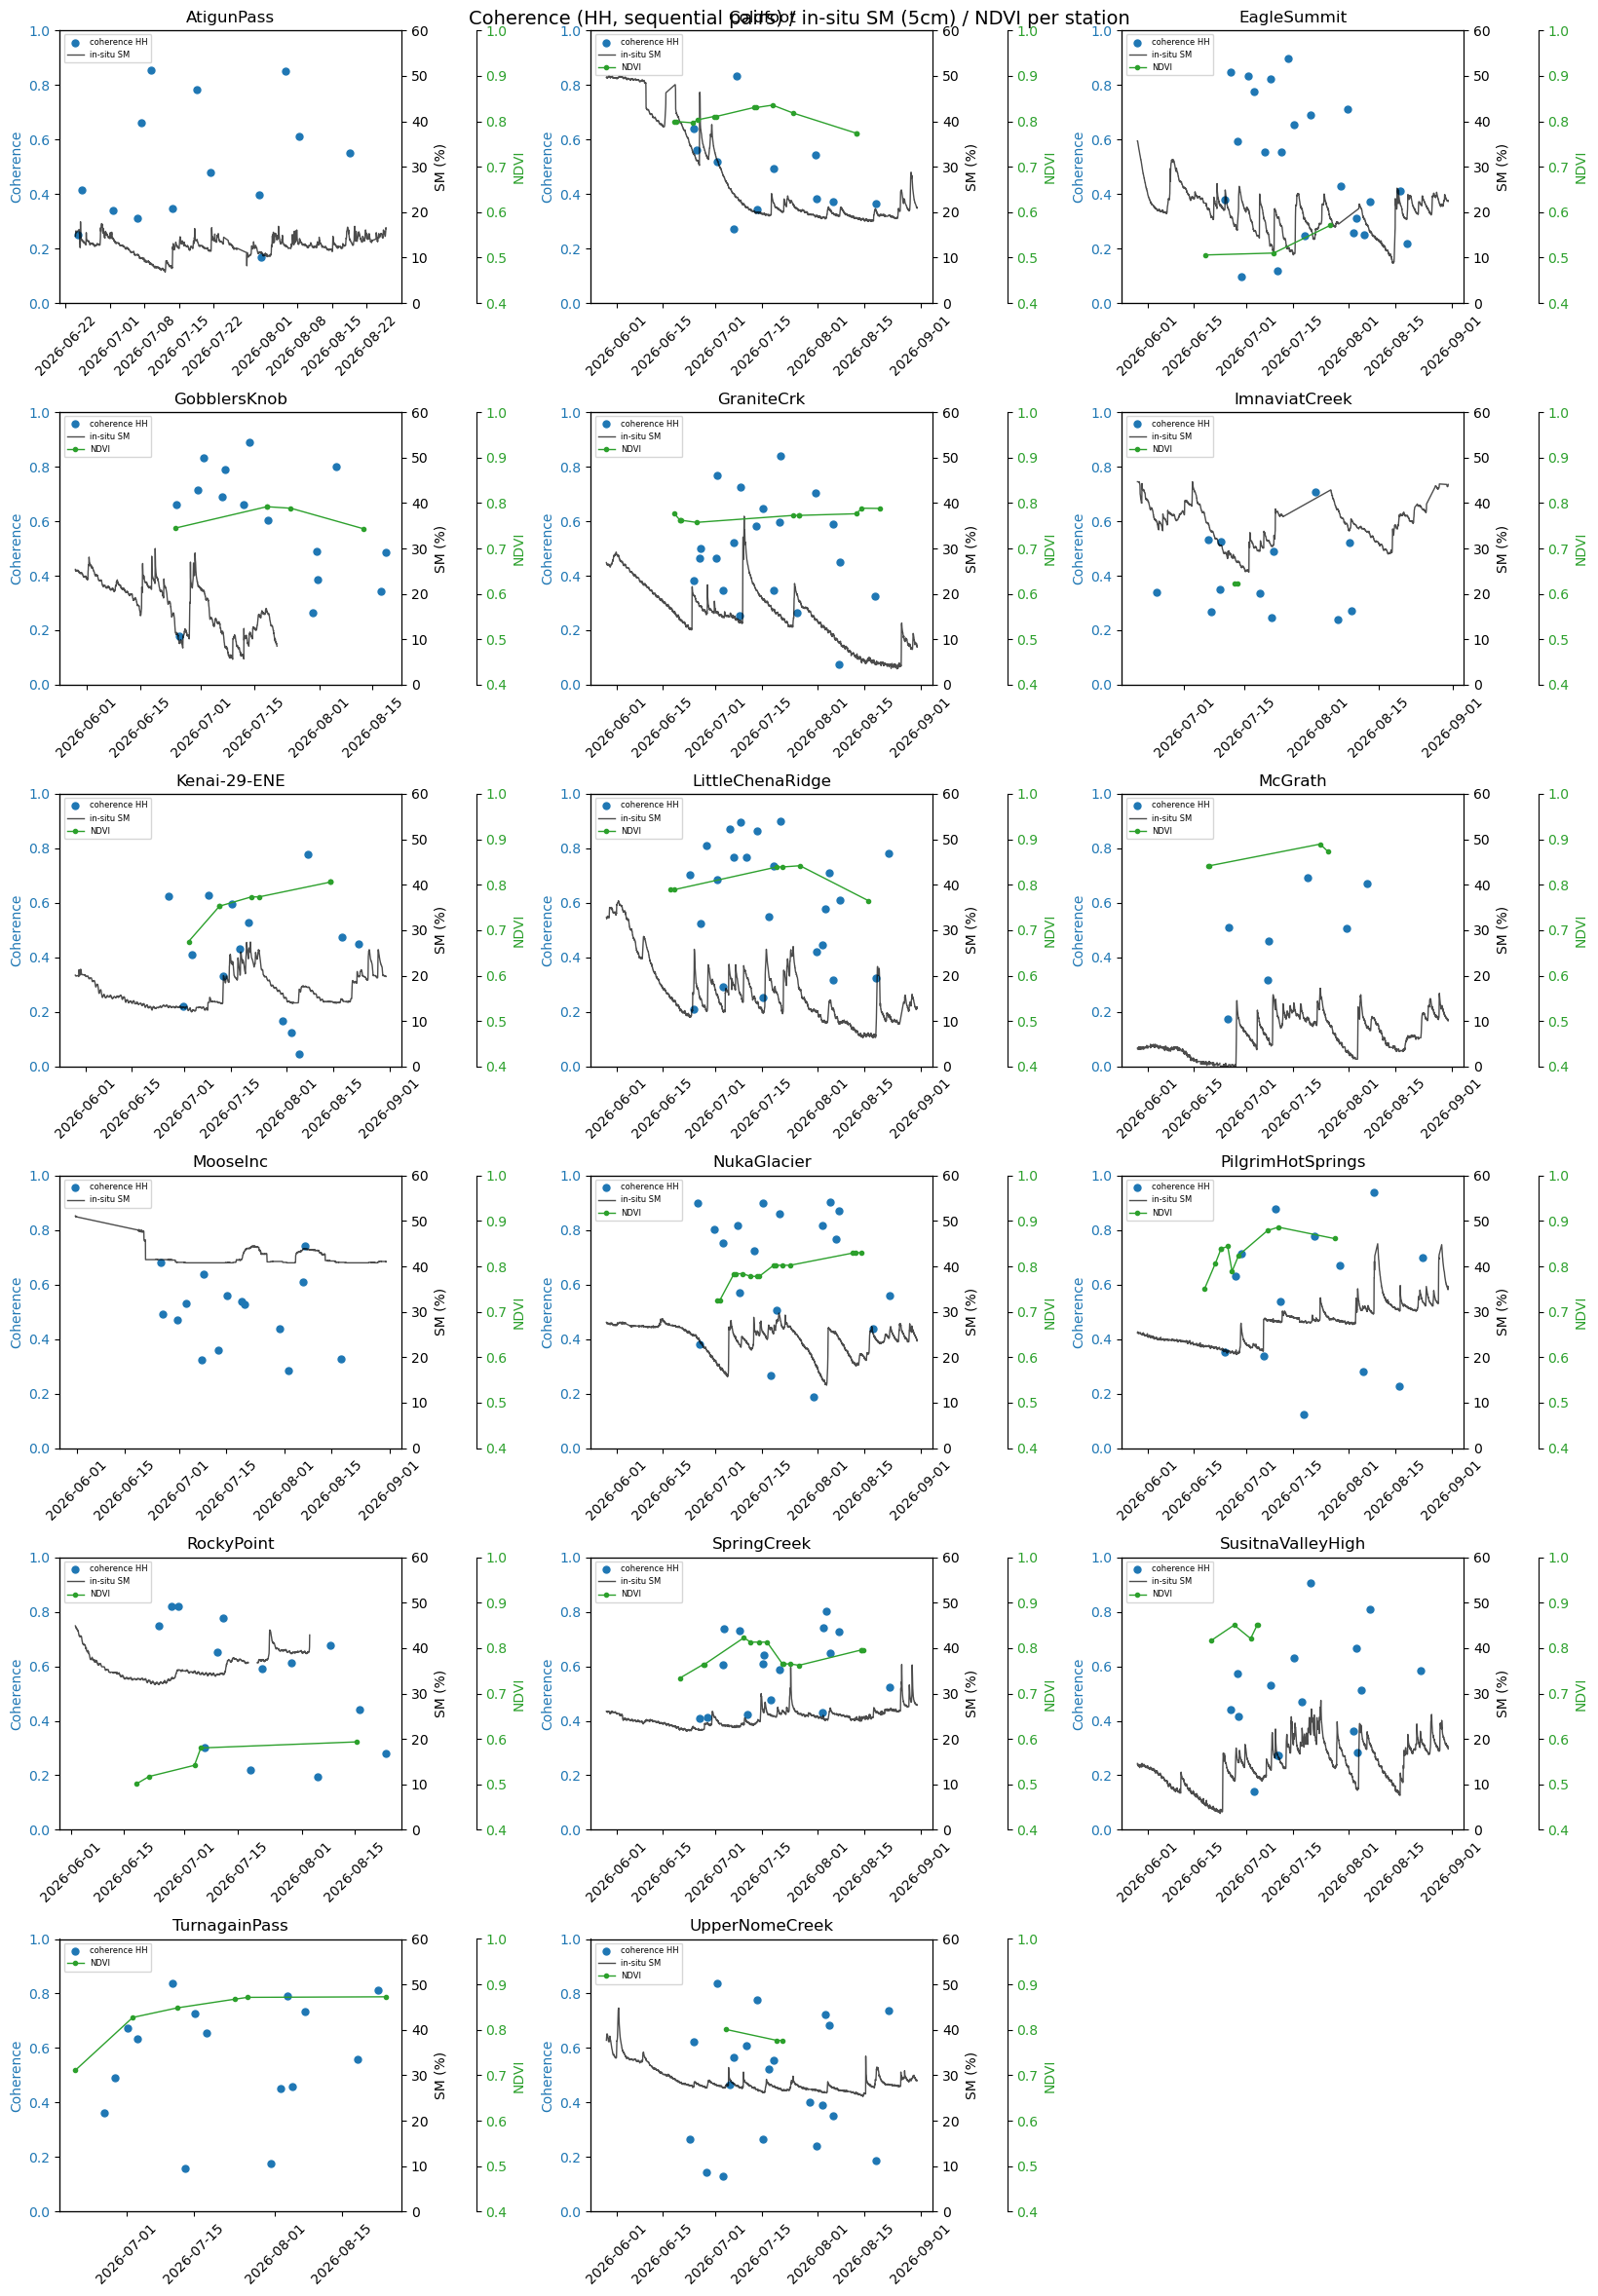

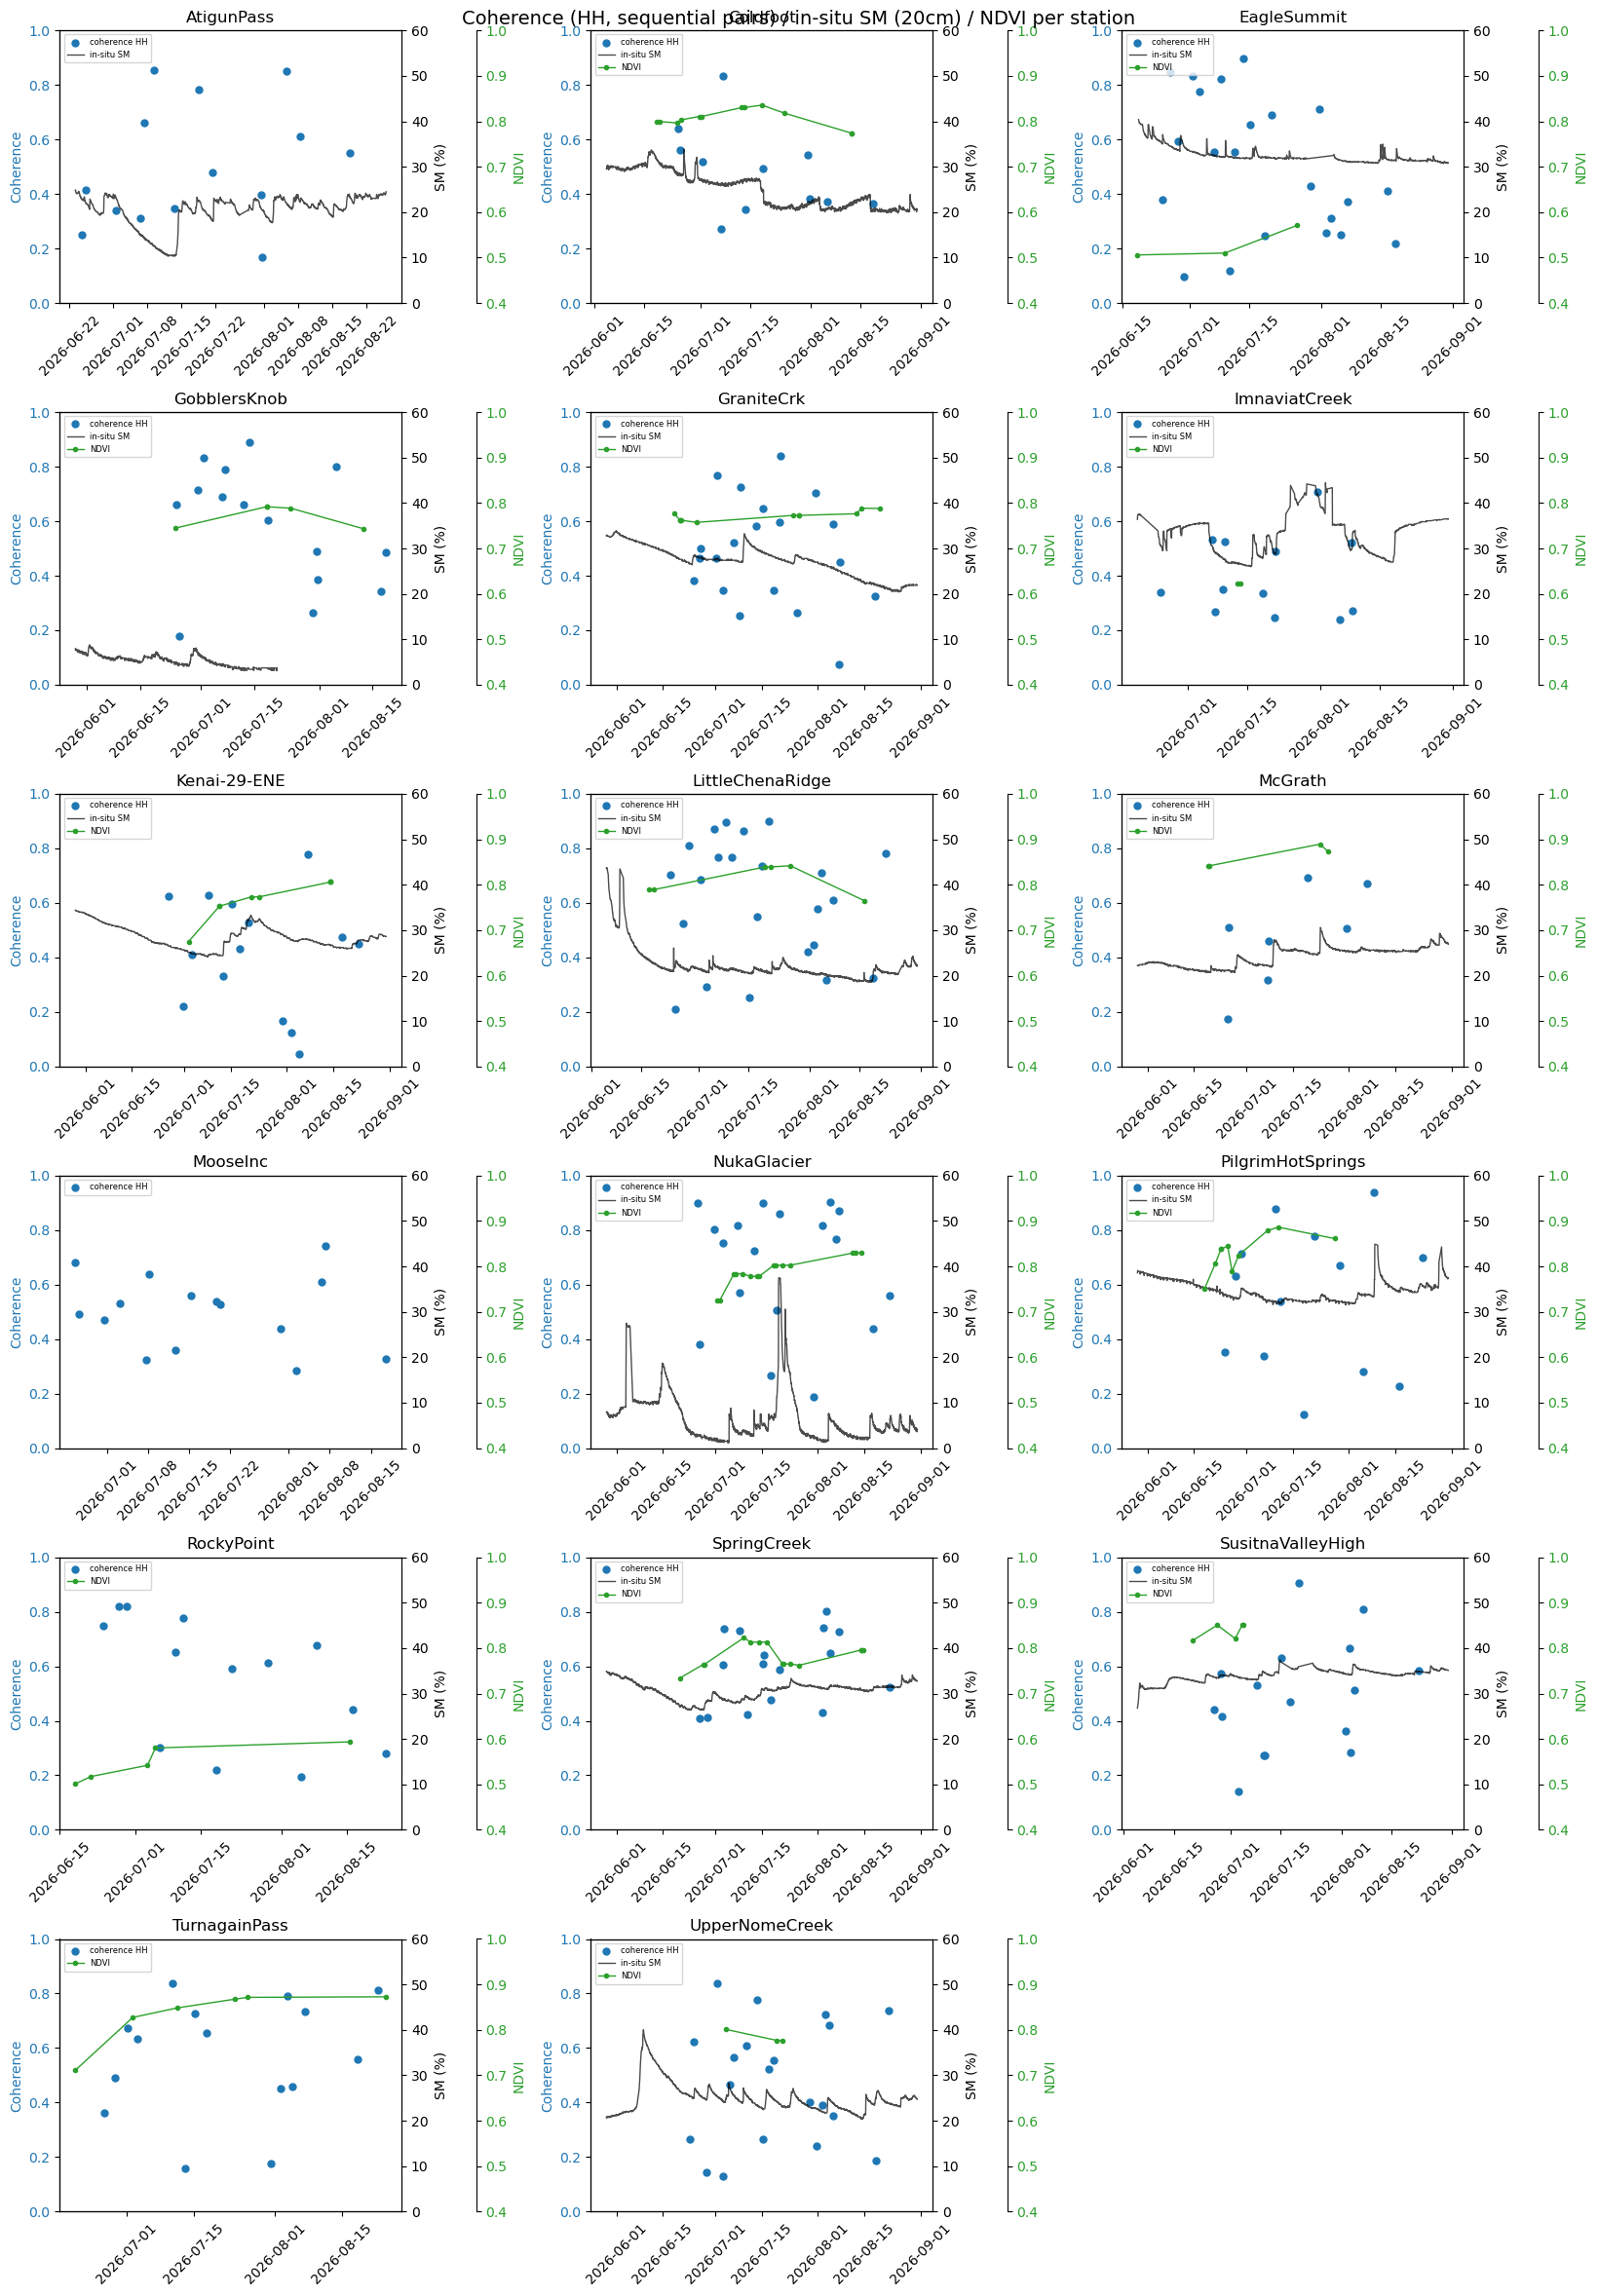

In [13]:
require_globals("coherence_by_station", "MIN_BASELINE_DAYS", "read_insitu", "read_ndvi")

COH_YLIM = (0, 1)
SM_YLIM = (0, 60)
NDVI_YLIM = (0.4, 1.0)


def sequential_pairs_only(df_coh, orbit_col="orbit_num"):
    """Keep only pairs whose two dates are adjacent in their own track's sorted
    acquisition list -- the full N(N-1)/2 matrix (every pair, used for the
    correlation checks elsewhere in this notebook) makes for a dense,
    overlapping-midpoint scatter here; the sequential subset gives one clean
    coherence trace per track instead."""
    kept = []
    for orbit, df_track in df_coh.groupby(orbit_col):
        dates = sorted(set(df_track["date_1"]) | set(df_track["date_2"]))
        date_idx = {d: i for i, d in enumerate(dates)}
        is_seq = (df_track["date_2"].map(date_idx) - df_track["date_1"].map(date_idx)) == 1
        kept.append(df_track[is_seq])
    return pd.concat(kept) if kept else df_coh.iloc[0:0]


def plot_station_overview(depth, pol="HH"):
    depth_label = "5cm" if depth == DEPTH_MAIN else "20cm"
    coh_col = f"coherence_{pol}"
    station_list = sorted(coherence_by_station.keys())
    ncols = 3
    nrows = int((len(station_list) + ncols - 1) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 5.5, nrows * 4), squeeze=False)
    axes = axes.flatten()

    for idx, station in enumerate(station_list):
        ax1 = axes[idx]
        ax2 = ax1.twinx()
        ax3 = ax1.twinx()
        ax3.spines["right"].set_position(("outward", 55))

        df_coh = coherence_by_station[station]
        df_coh = df_coh[df_coh["temporal_baseline_days"] >= MIN_BASELINE_DAYS]
        df_coh = sequential_pairs_only(df_coh, "orbit_num")
        valid_coh = df_coh[coh_col].notna()
        mid_dates = df_coh.loc[valid_coh, "date_1"] + (df_coh.loc[valid_coh, "date_2"] - df_coh.loc[valid_coh, "date_1"]) / 2
        ax1.scatter(mid_dates, df_coh.loc[valid_coh, coh_col], color="tab:blue", s=25, zorder=3, label=f"coherence {pol}")
        ax1.set_ylim(*COH_YLIM)
        ax1.set_ylabel("Coherence", color="tab:blue")
        ax1.tick_params(axis="y", labelcolor="tab:blue")

        sm_series = read_insitu(station, depth)
        if sm_series is not None:
            ax2.plot(sm_series.index, sm_series.values * 100, color="black", linewidth=1, alpha=0.7, label="in-situ SM")
        ax2.set_ylim(*SM_YLIM)
        ax2.set_ylabel("SM (%)", color="black")
        ax2.tick_params(axis="y", labelcolor="black")

        ndvi_series = read_ndvi(station)
        if ndvi_series is not None:
            ax3.plot(ndvi_series.index, ndvi_series.values, color="tab:green", linewidth=1,
                      marker="o", markersize=3, label="NDVI")
        ax3.set_ylim(*NDVI_YLIM)
        ax3.set_ylabel("NDVI", color="tab:green")
        ax3.tick_params(axis="y", labelcolor="tab:green")

        ax1.set_title(station)
        ax1.tick_params(axis="x", rotation=45)

        h1, l1 = ax1.get_legend_handles_labels()
        h2, l2 = ax2.get_legend_handles_labels()
        h3, l3 = ax3.get_legend_handles_labels()
        ax1.legend(h1 + h2 + h3, l1 + l2 + l3, fontsize=6, loc="upper left")

    for idx in range(len(station_list), len(axes)):
        axes[idx].axis("off")

    fig.suptitle(f"Coherence ({pol}, sequential pairs) / in-situ SM ({depth_label}) / NDVI per station", fontsize=14)
    fig.tight_layout()
    plt.show()


plot_station_overview(DEPTH_MAIN)
plot_station_overview(DEPTH_SECONDARY)


<hr>

## Summary

`r_coh_{5cm,20cm}_{HH,HV}` and `r_clo_{5cm,20cm}_{HH,HV}` hold the per-station
Pearson correlations computed above, one set per (depth, polarization)
combination. Both HH (co-pol) and HV (cross-pol) are compared -- HV is more
sensitive to vegetation volume scattering than to soil dielectric properties, so
a weaker HV relationship at a heavily-vegetated station (several of these are
shrubland/lichen-moss cover) versus a stronger HH one would be a meaningful,
physically-grounded signal, not just noise. Section 8 pools all 8 combinations
into `coherence_summary`/`closure_summary` to show which (depth, polarization)
performs best overall, rather than eyeballing it across the per-station grids.
Section 9 runs the analogous check against NDVI instead of soil moisture --
`r_ndvi_{HH,HV}` (per-station R) and `ndvi_coherence_stats` (the same numbers
plus mean NDVI/dNDVI/coherence and usable pair counts, one row per
station x polarization). Section 10 puts coherence, in-situ SM, and NDVI on
one fixed-range timeline per station, for a direct visual station-to-station
comparison rather than a correlation number.

Every number here comes from the already-computed `alaska_GSLC_coherence_closure/`
CSVs (and, for Sections 9-10, `alaska_HLS_ndvi/`) -- re-run notebook 04 (and 05)
in `Earsel26_NISAR-main` first if you want this to reflect newly downloaded
acquisitions, then just re-run this notebook (cheap, purely local).

<hr>